In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Memuat hasil Rule-Based terbaru tanpa TVOC
df_rule = pd.read_csv(
    r"C:\AI-Anomaly-Detection\outputs\hasil_rule_based_detection_no_tvoc.csv"
)

# Memuat hasil Hybrid AI terbaru tanpa TVOC
df_hybrid = pd.read_csv(
    r"C:\AI-Anomaly-Detection\outputs\hasil_hybrid_ai_testing_no_tvoc.csv"
)

# Mengubah kolom waktu menjadi datetime
df_rule["waktu_tercatat"] = pd.to_datetime(df_rule["waktu_tercatat"])
df_hybrid["waktu_tercatat"] = pd.to_datetime(df_hybrid["waktu_tercatat"])

print("===== PEMERIKSAAN DATA =====")

print("Data Rule-Based:", df_rule.shape)
print("Data Hybrid AI:", df_hybrid.shape)

print("\nJumlah sesi Rule-Based:", df_rule["session_id"].nunique())
print("Jumlah sesi Hybrid AI:", df_hybrid["session_id"].nunique())

print("\nJumlah data testing:", len(df_hybrid))

print("\nKolom pada data Hybrid AI:")
print(df_hybrid.columns.tolist())

===== PEMERIKSAAN DATA =====
Data Rule-Based: (38531, 31)
Data Hybrid AI: (11415, 37)

Jumlah sesi Rule-Based: 52
Jumlah sesi Hybrid AI: 11

Jumlah data testing: 11415

Kolom pada data Hybrid AI:
['id_monitoring_udara', 'suhu', 'kelembaban', 'pm10', 'pm25', 'barometer', 'tvoc', 'waktu_tercatat', 'gap_sec', 'session_id', 'tvoc_duration', 'tvoc_change_flag', 'tvoc_delta', 'barometer_duration', 'barometer_change_flag', 'barometer_delta', 'pm10_duration', 'pm10_change_flag', 'pm10_delta', 'pm25_duration', 'pm25_change_flag', 'pm25_delta', 'gap_panjang_flag', 'awal_sesi_flag', 'pm10_delta_next', 'pm25_delta_next', 'kandidat_spike', 'stuck_value', 'unusual_value', 'rule_based_anomaly', 'kombinasi_deteksi', 'prediksi_if', 'skor_if', 'ai_anomaly', 'perbandingan_deteksi', 'kategori_hybrid', 'hybrid_anomaly']


In [29]:
print("===== DISTRIBUSI RULE-BASED PADA DATA TESTING =====")

print(
    df_hybrid["rule_based_anomaly"]
    .value_counts()
    .rename(index={
        True: "Kandidat Anomali",
        False: "Normal"
    })
)

print("\n===== DISTRIBUSI ISOLATION FOREST =====")

print(
    df_hybrid["ai_anomaly"]
    .value_counts()
    .rename(index={
        True: "Kandidat Anomali",
        False: "Normal"
    })
)

print("\n===== DISTRIBUSI HYBRID AI =====")

print(
    df_hybrid["hybrid_anomaly"]
    .value_counts()
    .rename(index={
        True: "Kandidat Anomali",
        False: "Normal"
    })
)

print("\n===== KATEGORI HYBRID AI =====")

print(df_hybrid["kategori_hybrid"].value_counts())

===== DISTRIBUSI RULE-BASED PADA DATA TESTING =====
rule_based_anomaly
Normal              8804
Kandidat Anomali    2611
Name: count, dtype: int64

===== DISTRIBUSI ISOLATION FOREST =====
ai_anomaly
Normal              9883
Kandidat Anomali    1532
Name: count, dtype: int64

===== DISTRIBUSI HYBRID AI =====
hybrid_anomaly
Normal              8012
Kandidat Anomali    3403
Name: count, dtype: int64

===== KATEGORI HYBRID AI =====
kategori_hybrid
Normal                       8012
Anomali - Rule-Based saja    1871
Anomali - AI saja             792
Anomali - Rule-Based + AI     740
Name: count, dtype: int64


In [30]:

total_data = len(df_hybrid)

ringkasan_evaluasi = pd.DataFrame({
    "Metode": [
        "Rule-Based",
        "Isolation Forest",
        "Hybrid AI"
    ],
    "Kandidat Anomali": [
        df_hybrid["rule_based_anomaly"].sum(),
        df_hybrid["ai_anomaly"].sum(),
        df_hybrid["hybrid_anomaly"].sum()
    ],
    "Data Normal": [
        (~df_hybrid["rule_based_anomaly"]).sum(),
        (~df_hybrid["ai_anomaly"]).sum(),
        (~df_hybrid["hybrid_anomaly"]).sum()
    ]
})

ringkasan_evaluasi["Persentase Anomali (%)"] = (
    ringkasan_evaluasi["Kandidat Anomali"]
    / total_data * 100
).round(2)

ringkasan_evaluasi["Persentase Normal (%)"] = (
    ringkasan_evaluasi["Data Normal"]
    / total_data * 100
).round(2)

print("===== PERBANDINGAN HASIL DETEKSI =====")
display(ringkasan_evaluasi)

print("\nTotal data testing:", total_data)


===== PERBANDINGAN HASIL DETEKSI =====


,Metode,Kandidat Anomali,Data Normal,Persentase Anomali (%),Persentase Normal (%)
0,Rule-Based,2611,8804,22.87,77.13
1,Isolation Forest,1532,9883,13.42,86.58
2,Hybrid AI,3403,8012,29.81,70.19



Total data testing: 11415


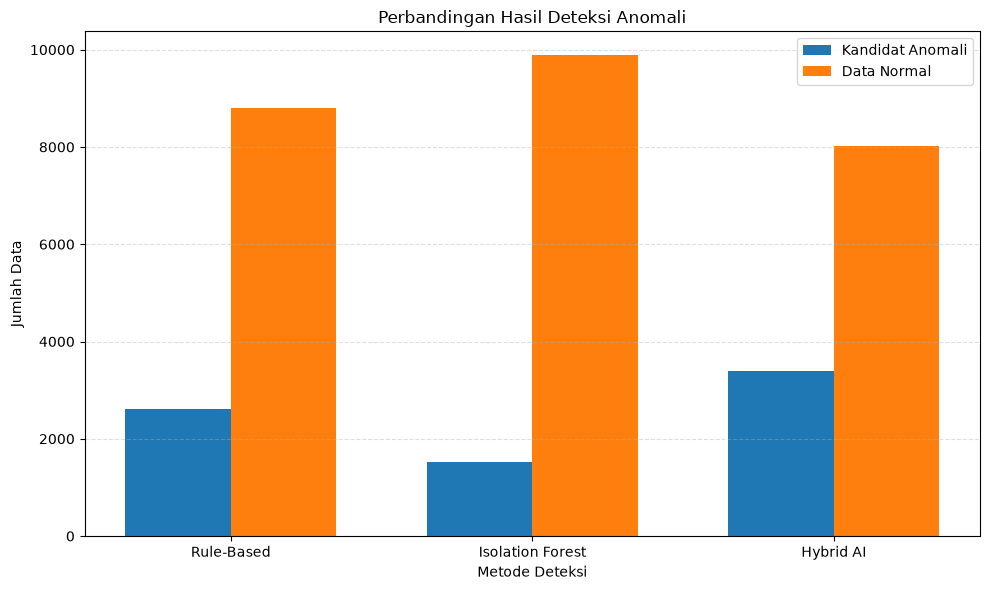

In [31]:

# Menyiapkan data visualisasi
metode = ringkasan_evaluasi["Metode"]

x = np.arange(len(metode))
lebar = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - lebar/2,
    ringkasan_evaluasi["Kandidat Anomali"],
    lebar,
    label="Kandidat Anomali"
)

plt.bar(
    x + lebar/2,
    ringkasan_evaluasi["Data Normal"],
    lebar,
    label="Data Normal"
)

plt.title("Perbandingan Hasil Deteksi Anomali")
plt.xlabel("Metode Deteksi")
plt.ylabel("Jumlah Data")
plt.xticks(x, metode)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


In [32]:

# Membuat tabel silang hasil deteksi
tabel_kesesuaian = pd.crosstab(
    df_hybrid["rule_based_anomaly"].map({
        True: "Anomali Rule-Based",
        False: "Normal Rule-Based"
    }),
    df_hybrid["ai_anomaly"].map({
        True: "Anomali Isolation Forest",
        False: "Normal Isolation Forest"
    })
)

print("===== KESESUAIAN DETEKSI ANTAR-METODE =====")
display(tabel_kesesuaian)

print("\n===== RINGKASAN KESESUAIAN =====")

print(
    "Terdeteksi kedua metode:",
    ((df_hybrid["rule_based_anomaly"]) &
     (df_hybrid["ai_anomaly"])).sum()
)

print(
    "Rule-Based saja:",
    ((df_hybrid["rule_based_anomaly"]) &
     (~df_hybrid["ai_anomaly"])).sum()
)

print(
    "Isolation Forest saja:",
    ((~df_hybrid["rule_based_anomaly"]) &
     (df_hybrid["ai_anomaly"])).sum()
)

print(
    "Normal menurut kedua metode:",
    ((~df_hybrid["rule_based_anomaly"]) &
     (~df_hybrid["ai_anomaly"])).sum()
)


===== KESESUAIAN DETEKSI ANTAR-METODE =====


ai_anomaly,Anomali Isolation Forest,Normal Isolation Forest
rule_based_anomaly,,
Anomali Rule-Based,740,1871
Normal Rule-Based,792,8012



===== RINGKASAN KESESUAIAN =====
Terdeteksi kedua metode: 740
Rule-Based saja: 1871
Isolation Forest saja: 792
Normal menurut kedua metode: 8012


In [33]:

total_data = len(df_hybrid)

kedua_anomali = (
    df_hybrid["rule_based_anomaly"] &
    df_hybrid["ai_anomaly"]
).sum()

keduanya_normal = (
    ~df_hybrid["rule_based_anomaly"] &
    ~df_hybrid["ai_anomaly"]
).sum()

sepakat = kedua_anomali + keduanya_normal
tidak_sepakat = total_data - sepakat

gabungan_anomali = df_hybrid["hybrid_anomaly"].sum()

tingkat_kesepakatan = sepakat / total_data * 100
tingkat_perbedaan = tidak_sepakat / total_data * 100
overlap_anomali = kedua_anomali / gabungan_anomali * 100

print("===== ANALISIS KESEPAKATAN METODE =====")

print("Total data testing:", total_data)

print(
    f"Data yang disepakati: {sepakat} "
    f"({tingkat_kesepakatan:.2f}%)"
)

print(
    f"Data yang berbeda: {tidak_sepakat} "
    f"({tingkat_perbedaan:.2f}%)"
)

print(
    f"Overlap kandidat anomali: {kedua_anomali} "
    f"({overlap_anomali:.2f}% dari gabungan anomali)"
)


===== ANALISIS KESEPAKATAN METODE =====
Total data testing: 11415
Data yang disepakati: 8752 (76.67%)
Data yang berbeda: 2663 (23.33%)
Overlap kandidat anomali: 740 (21.75% dari gabungan anomali)


In [34]:

ringkasan_sesi = (
    df_hybrid
    .groupby("session_id")
    .agg(
        jumlah_data=("hybrid_anomaly", "count"),
        rule_based=("rule_based_anomaly", "sum"),
        isolation_forest=("ai_anomaly", "sum"),
        hybrid_ai=("hybrid_anomaly", "sum")
    )
)

# Menghitung persentase kandidat anomali per sesi
ringkasan_sesi["persentase_hybrid"] = (
    ringkasan_sesi["hybrid_ai"]
    / ringkasan_sesi["jumlah_data"] * 100
).round(2)

ringkasan_sesi = ringkasan_sesi.sort_values(
    "persentase_hybrid",
    ascending=False
)

print("===== DISTRIBUSI DETEKSI ANOMALI PER SESI =====")
display(ringkasan_sesi)

print("\nJumlah sesi testing:", len(ringkasan_sesi))
print(
    "Total kandidat Hybrid AI:",
    ringkasan_sesi["hybrid_ai"].sum()
)


===== DISTRIBUSI DETEKSI ANOMALI PER SESI =====


,jumlah_data,rule_based,isolation_forest,hybrid_ai,persentase_hybrid
session_id,,,,,
48,1115,1115,298,1115,100.00
50,1238,1238,345,1238,100.00
46,1332,76,163,204,15.32
44,1287,64,142,183,14.22
42,1150,0,161,161,14.00
43,1214,32,136,151,12.44
49,1271,84,88,152,11.96
52,116,0,11,11,9.48
47,1273,1,119,119,9.35



Jumlah sesi testing: 11
Total kandidat Hybrid AI: 3403


In [35]:
for sesi in [48, 50]:

    data_sesi = df_hybrid[
        df_hybrid["session_id"] == sesi
    ]

    print(f"\n===== PEMERIKSAAN SESI {sesi} =====")

    print("\nKategori deteksi:")
    print(data_sesi["kombinasi_deteksi"].value_counts())

    print("\nJumlah deteksi setiap sensor:")
    print(
        data_sesi[
            [
                "kandidat_spike",
                "stuck_value",
                "unusual_value"
            ]
        ].sum()
    )

    print("\nStatistik sensor:")
    display(
        data_sesi[
            ["suhu", "kelembaban", "pm10", "pm25", "barometer"]
        ].describe().round(2)
    )


===== PEMERIKSAAN SESI 48 =====

Kategori deteksi:
kombinasi_deteksi
Unusual            1114
Spike + Unusual       1
Name: count, dtype: int64

Jumlah deteksi setiap sensor:
kandidat_spike       1
stuck_value          0
unusual_value     1115
dtype: int64

Statistik sensor:


,suhu,kelembaban,pm10,pm25,barometer
count,1115.00,1115.00,1115.00,1115.00,1115.00
mean,32.16,54.82,35.40,16.89,756.29
std,3.91,9.62,13.21,5.70,1.10
min,28.30,34.00,12.00,5.00,754.22
25%,29.49,49.00,23.00,11.00,755.42
50%,30.39,59.00,35.00,17.00,756.41
75%,33.91,62.00,48.00,22.00,757.13
max,41.11,65.00,69.00,34.00,758.11



===== PEMERIKSAAN SESI 50 =====

Kategori deteksi:
kombinasi_deteksi
Unusual            1234
Spike + Unusual       4
Name: count, dtype: int64

Jumlah deteksi setiap sensor:
kandidat_spike       4
stuck_value          0
unusual_value     1238
dtype: int64

Statistik sensor:


,suhu,kelembaban,pm10,pm25,barometer
count,1238.00,1238.00,1238.00,1238.00,1238.00
mean,31.26,59.21,26.23,12.73,753.35
std,4.71,14.05,11.20,5.48,1.23
min,26.12,32.00,0.00,0.00,750.57
25%,27.11,46.00,17.00,9.00,752.52
50%,29.59,65.00,30.00,15.00,753.67
75%,34.46,73.00,34.00,17.00,754.37
max,42.50,76.00,58.00,27.00,754.88


In [36]:
for sesi in [48, 50]:

    data_sesi = df_hybrid[
        df_hybrid["session_id"] == sesi
    ]

    print(f"\n===== DETAIL UNUSUAL VALUE SESI {sesi} =====")

    for kolom in [
        "suhu",
        "kelembaban",
        "pm10",
        "pm25",
        "barometer"
    ]:

        print(
            kolom,
            ":",
            data_sesi[
                f"unusual_{kolom}"
            ].sum()
            if f"unusual_{kolom}" in data_sesi.columns
            else "Kolom tidak tersedia"
        )


===== DETAIL UNUSUAL VALUE SESI 48 =====
suhu : Kolom tidak tersedia
kelembaban : Kolom tidak tersedia
pm10 : Kolom tidak tersedia
pm25 : Kolom tidak tersedia
barometer : Kolom tidak tersedia

===== DETAIL UNUSUAL VALUE SESI 50 =====
suhu : Kolom tidak tersedia
kelembaban : Kolom tidak tersedia
pm10 : Kolom tidak tersedia
pm25 : Kolom tidak tersedia
barometer : Kolom tidak tersedia


In [37]:
# Memeriksa dua sesi dengan deteksi 100%
sesi_pemeriksaan = [48, 50]

kolom_flag = [
    "kandidat_spike",
    "stuck_value",
    "unusual_value",
    "ai_anomaly",
    "kategori_hybrid"
]

# Ambil hanya kolom yang tersedia
kolom_tersedia = [
    kolom for kolom in kolom_flag
    if kolom in df_hybrid.columns
]

kolom_tidak_tersedia = [
    kolom for kolom in kolom_flag
    if kolom not in df_hybrid.columns
]

print("Kolom yang digunakan:", kolom_tersedia)
print("Kolom yang tidak tersedia:", kolom_tidak_tersedia)

data_pemeriksaan = df_hybrid[
    df_hybrid["session_id"].isin(sesi_pemeriksaan)
]

print("\n===== PENYEBAB DETEKSI SESSION 48 DAN 50 =====")

display(
    data_pemeriksaan
    .groupby("session_id")[kolom_tersedia]
    .sum(numeric_only=True)
)

print("\n===== PERSENTASE SETIAP FLAG =====")

display(
    (
        data_pemeriksaan
        .groupby("session_id")[kolom_tersedia]
        .mean(numeric_only=True) * 100
    ).round(2)
)

Kolom yang digunakan: ['kandidat_spike', 'stuck_value', 'unusual_value', 'ai_anomaly', 'kategori_hybrid']
Kolom yang tidak tersedia: []

===== PENYEBAB DETEKSI SESSION 48 DAN 50 =====


,kandidat_spike,stuck_value,unusual_value,ai_anomaly
session_id,,,,
48,1,0,1115,298
50,4,0,1238,345



===== PERSENTASE SETIAP FLAG =====


,kandidat_spike,stuck_value,unusual_value,ai_anomaly
session_id,,,,
48,0.09,0.0,100.0,26.73
50,0.32,0.0,100.0,27.87


In [38]:

sensor_pemeriksaan = [
    "barometer",
    "tvoc",
    "suhu",
    "kelembaban",
    "pm10",
    "pm25"
]

ringkasan_sensor_sesi = (
    df_hybrid[
        df_hybrid["session_id"].isin([48, 50])
    ]
    .groupby("session_id")[sensor_pemeriksaan]
    .agg(["min", "median", "max", "nunique"])
)

print("===== KARAKTERISTIK SENSOR SESSION 48 DAN 50 =====")
display(ringkasan_sensor_sesi)


===== KARAKTERISTIK SENSOR SESSION 48 DAN 50 =====


barometer                            tvoc                          \
                 min  median     max nunique     min  median     max nunique   
session_id                                                                     
48            754.22  756.41  758.11     333   83.45  100.22  125.42       6   
50            750.57  753.67  754.88     344  117.01  133.84  167.57       7   

             suhu         ... kelembaban          pm10                       \
              min median  ...        max nunique   min median   max nunique   
session_id                ...                                                 
48          28.30  30.39  ...         65      32  12.0   35.0  69.0      55   
50          26.12  29.59  ...         76      45   0.0   30.0  58.0      49   

           pm25                       
            min median   max nunique  
session_id                            
48          5.0   17.0  34.0      28  
50          0.0   15.0  27.0      25  

[2 rows x 24 columns]

In [39]:

# Membandingkan median sensor pada setiap sesi testing
perbandingan_sensor = (
    df_hybrid
    .groupby("session_id")
    .agg(
        median_barometer=("barometer", "median"),
        min_barometer=("barometer", "min"),
        max_barometer=("barometer", "max"),
        median_tvoc=("tvoc", "median"),
        min_tvoc=("tvoc", "min"),
        max_tvoc=("tvoc", "max")
    )
)

print("===== PERBANDINGAN BAROMETER DAN TVOC ANTAR-SESI =====")
display(perbandingan_sensor.round(2))


===== PERBANDINGAN BAROMETER DAN TVOC ANTAR-SESI =====


,median_barometer,min_barometer,max_barometer,median_tvoc,min_tvoc,max_tvoc
session_id,,,,,,
42,705.02,702.38,706.33,696.08,678.31,722.78
43,700.96,699.07,702.69,740.63,722.78,767.45
44,698.51,696.64,699.80,776.40,758.50,794.34
45,703.83,701.79,705.22,704.97,696.08,731.70
46,703.43,701.05,704.54,713.87,696.08,740.63
47,701.84,699.79,702.64,731.70,722.78,758.50
48,756.41,754.22,758.11,100.22,83.45,125.42
49,703.18,701.20,704.35,713.87,704.97,740.63
50,753.67,750.57,754.88,133.84,117.01,167.57


In [40]:

# Memeriksa waktu dan nilai sensor pada batas sesi
sesi_transisi = [47, 48, 49, 50, 51]

kolom_pemeriksaan = [
    "session_id",
    "waktu_tercatat",
    "barometer",
    "tvoc",
    "suhu",
    "kelembaban",
    "pm10",
    "pm25"
]

data_transisi = df_hybrid[
    df_hybrid["session_id"].isin(sesi_transisi)
].sort_values(["session_id", "waktu_tercatat"])

print("===== 3 DATA PERTAMA SETIAP SESI =====")

display(
    data_transisi
    .groupby("session_id")
    .head(3)[kolom_pemeriksaan]
)

print("\n===== 3 DATA TERAKHIR SETIAP SESI =====")

display(
    data_transisi
    .groupby("session_id")
    .tail(3)[kolom_pemeriksaan]
)


===== 3 DATA PERTAMA SETIAP SESI =====


,session_id,waktu_tercatat,barometer,tvoc,suhu,kelembaban,pm10,pm25
6267,47,2026-11-02 10:28:49,702.57,722.78,29.09,51,25.0,11.0
6268,47,2026-11-02 10:29:54,702.49,722.78,29.09,50,24.0,12.0
6269,47,2026-11-02 10:30:58,702.49,722.78,29.19,49,24.0,12.0
7540,48,2026-11-04 11:08:27,756.38,100.22,37.24,41,24.0,13.0
7541,48,2026-11-04 11:09:30,756.32,100.22,37.44,40,27.0,14.0
7542,48,2026-11-04 11:10:33,756.35,100.22,37.54,40,29.0,14.0
8655,49,2026-11-09 10:27:35,703.94,704.97,37.34,37,39.0,18.0
8656,49,2026-11-09 10:28:39,703.90,704.97,37.83,37,39.0,18.0
8657,49,2026-11-09 10:29:42,703.96,704.97,38.23,35,36.0,17.0
9926,50,2026-11-12 10:21:17,753.44,133.84,37.93,43,16.0,4.0



===== 3 DATA TERAKHIR SETIAP SESI =====


,session_id,waktu_tercatat,barometer,tvoc,suhu,kelembaban,pm10,pm25
7537,47,2026-11-03 09:36:07,702.02,731.70,28.80,50,5.0,1.0
7538,47,2026-11-03 09:37:11,702.04,731.70,28.80,49,2.0,1.0
7539,47,2026-11-03 09:38:16,702.04,731.70,28.90,52,3.0,2.0
8652,48,2026-11-05 07:10:42,757.24,91.83,30.39,56,46.0,22.0
8653,48,2026-11-05 07:11:47,757.27,91.83,30.49,57,50.0,22.0
8654,48,2026-11-05 07:12:52,757.27,91.83,30.58,57,47.0,22.0
9923,49,2026-11-10 09:20:50,703.63,713.87,34.76,42,43.0,21.0
9924,49,2026-11-10 09:21:55,703.60,713.87,34.56,42,44.0,22.0
9925,49,2026-11-10 09:23:00,703.59,713.87,34.26,42,43.0,20.0
11161,50,2026-11-13 10:29:00,753.93,133.84,37.44,40,6.0,2.0


In [41]:

# Membandingkan median barometer dan TVOC seluruh sesi
perbandingan_semua_sesi = (
    df_rule
    .groupby("session_id")
    .agg(
        jumlah_data=("barometer", "count"),
        median_barometer=("barometer", "median"),
        median_tvoc=("tvoc", "median"),
        min_barometer=("barometer", "min"),
        max_barometer=("barometer", "max"),
        min_tvoc=("tvoc", "min"),
        max_tvoc=("tvoc", "max")
    )
)

perbandingan_semua_sesi["kelompok_data"] = np.where(
    perbandingan_semua_sesi.index <= 41,
    "Training",
    "Testing"
)

print("===== PERBANDINGAN SELURUH SESI =====")
display(perbandingan_semua_sesi.round(2))


===== PERBANDINGAN SELURUH SESI =====


,jumlah_data,median_barometer,median_tvoc,min_barometer,max_barometer,min_tvoc,max_tvoc,kelompok_data
session_id,,,,,,,,
1,1136,701.68,731.70,699.32,702.81,722.78,758.50,Training
2,1289,703.42,713.87,701.55,704.56,696.08,731.70,Training
3,282,697.98,776.40,697.46,699.88,758.50,785.37,Training
4,746,699.95,758.50,699.07,701.27,740.63,767.45,Training
5,1211,701.76,731.70,699.69,702.63,722.78,758.50,Training
6,1191,698.20,776.40,696.08,699.51,758.50,803.32,Training
7,1065,701.70,731.70,699.22,702.98,722.78,767.45,Training
8,1046,700.56,749.56,698.52,701.71,731.70,776.40,Training
9,1143,699.05,767.45,697.27,700.75,749.56,785.37,Training


In [42]:

import joblib

# Memuat model Hybrid AI versi tanpa TVOC
model_if = joblib.load(
    r"C:\AI-Anomaly-Detection\models\hybrid_isolation_forest_no_tvoc.joblib"
)

# 16 fitur yang digunakan saat pelatihan
feature_columns = [
    "suhu",
    "kelembaban",
    "pm10",
    "pm25",
    "barometer",
    "barometer_duration",
    "barometer_change_flag",
    "barometer_delta",
    "pm10_duration",
    "pm10_change_flag",
    "pm10_delta",
    "pm25_duration",
    "pm25_change_flag",
    "pm25_delta",
    "gap_panjang_flag",
    "awal_sesi_flag"
]

# Memilih sesi yang akan diperiksa
sesi_pemeriksaan = [12, 13, 15, 48, 50]

data_model = df_rule[
    df_rule["session_id"].isin(sesi_pemeriksaan)
].copy()

# Memastikan semua fitur tersedia
kolom_tidak_ada = [
    kolom for kolom in feature_columns
    if kolom not in data_model.columns
]

if kolom_tidak_ada:
    raise ValueError(f"Kolom fitur tidak ditemukan: {kolom_tidak_ada}")

# Mengambil fitur untuk prediksi
X_pemeriksaan = data_model[feature_columns]

# Prediksi Isolation Forest
data_model["prediksi_if"] = model_if.predict(X_pemeriksaan)
data_model["skor_if"] = model_if.decision_function(X_pemeriksaan)
data_model["ai_anomaly"] = data_model["prediksi_if"] == -1

# Ringkasan hasil per sesi
ringkasan_model_sesi = (
    data_model
    .groupby("session_id")
    .agg(
        jumlah_data=("ai_anomaly", "size"),
        jumlah_anomali_ai=("ai_anomaly", "sum"),
        median_skor=("skor_if", "median"),
        skor_terendah=("skor_if", "min"),
        skor_tertinggi=("skor_if", "max")
    )
)

ringkasan_model_sesi["persentase_anomali"] = (
    ringkasan_model_sesi["jumlah_anomali_ai"]
    / ringkasan_model_sesi["jumlah_data"] * 100
)

print("===== PENILAIAN ISOLATION FOREST PER SESI =====")
display(ringkasan_model_sesi.round(4))


===== PENILAIAN ISOLATION FOREST PER SESI =====


,jumlah_data,jumlah_anomali_ai,median_skor,skor_terendah,skor_tertinggi,persentase_anomali
session_id,,,,,,
12,7,0,0.0594,0.0307,0.0719,0.0000
13,1011,229,0.0447,-0.1577,0.0953,22.6508
15,1155,317,0.0322,-0.1394,0.1019,27.4459
48,1115,298,0.0341,-0.1264,0.0937,26.7265
50,1238,345,0.0327,-0.1453,0.0971,27.8675


In [43]:

# Membandingkan karakteristik sensor berdasarkan prediksi AI
kolom_sensor = [
    "suhu", "kelembaban", "pm10",
    "pm25", "barometer", "tvoc"
]

perbandingan_ai_sensor = (
    data_model[
        data_model["session_id"].isin([48, 50])
    ]
    .groupby(["session_id", "ai_anomaly"])[kolom_sensor]
    .median()
)

print("===== MEDIAN SENSOR BERDASARKAN PREDIKSI AI =====")
display(perbandingan_ai_sensor.round(2))


===== MEDIAN SENSOR BERDASARKAN PREDIKSI AI =====


suhu  kelembaban  pm10  pm25  barometer    tvoc
session_id ai_anomaly                                                  
48         False       30.39        60.0  35.0  17.0     756.45  100.22
           True        30.68        58.0  37.5  17.0     756.29  108.61
50         False       28.90        66.0  31.0  16.0     753.75  133.84
           True        33.46        49.0  19.0  10.0     753.24  142.26

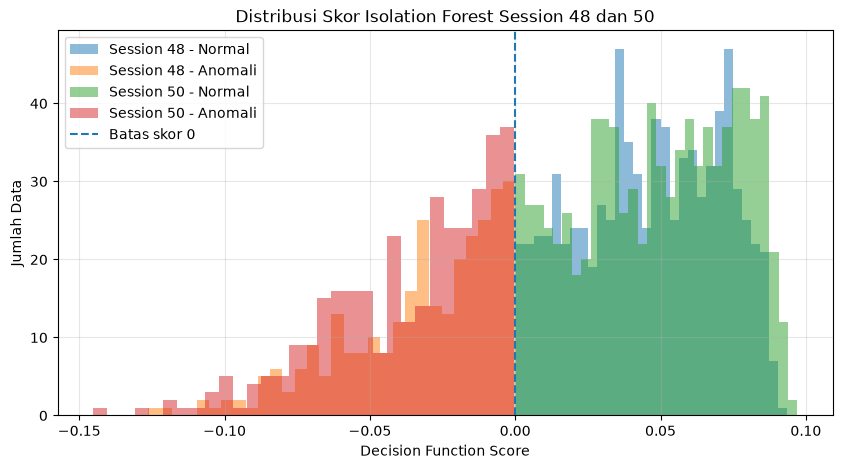

In [44]:

# Membandingkan distribusi skor AI per sesi
plt.figure(figsize=(10, 5))

for sesi in [48, 50]:
    subset = data_model[data_model["session_id"] == sesi]

    plt.hist(
        subset.loc[subset["ai_anomaly"] == False, "skor_if"],
        bins=30,
        alpha=0.5,
        label=f"Session {sesi} - Normal"
    )

    plt.hist(
        subset.loc[subset["ai_anomaly"] == True, "skor_if"],
        bins=30,
        alpha=0.5,
        label=f"Session {sesi} - Anomali"
    )

plt.axvline(0, linestyle="--", label="Batas skor 0")
plt.title("Distribusi Skor Isolation Forest Session 48 dan 50")
plt.xlabel("Decision Function Score")
plt.ylabel("Jumlah Data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [45]:
print("===== KOLOM DATA RULE-BASED =====")

for kolom in df_rule.columns:
    if "unusual" in kolom.lower():
        print(kolom)

print("\n===== KOLOM DATA HYBRID =====")

for kolom in df_hybrid.columns:
    if "unusual" in kolom.lower():
        print(kolom)

===== KOLOM DATA RULE-BASED =====
unusual_value

===== KOLOM DATA HYBRID =====
unusual_value


In [46]:
print("===== PEMERIKSAAN BATAS IQR =====")

for kolom in [
    "suhu",
    "kelembaban",
    "pm10",
    "pm25",
    "barometer"
]:
    print(f"\nSensor: {kolom}")

    q1 = df_rule[kolom].quantile(0.25)
    q3 = df_rule[kolom].quantile(0.75)
    iqr = q3 - q1

    batas_bawah = q1 - (1.5 * iqr)
    batas_atas = q3 + (1.5 * iqr)

    print("Batas bawah:", round(batas_bawah, 2))
    print("Batas atas :", round(batas_atas, 2))

===== PEMERIKSAAN BATAS IQR =====

Sensor: suhu
Batas bawah: 14.69
Batas atas : 39.33

Sensor: kelembaban
Batas bawah: 20.5
Batas atas : 96.5

Sensor: pm10
Batas bawah: -16.0
Batas atas : 80.0

Sensor: pm25
Batas bawah: -4.0
Batas atas : 36.0

Sensor: barometer
Batas bawah: 694.66
Batas atas : 709.14


In [47]:
for sesi in [48, 50]:

    data_sesi = df_hybrid[
        df_hybrid["session_id"] == sesi
    ]

    print(f"\n===== JUMLAH NILAI DI LUAR IQR SESI {sesi} =====")

    for kolom in [
        "suhu",
        "kelembaban",
        "pm10",
        "pm25",
        "barometer"
    ]:

        q1 = df_rule[kolom].quantile(0.25)
        q3 = df_rule[kolom].quantile(0.75)
        iqr = q3 - q1

        batas_bawah = q1 - (1.5 * iqr)
        batas_atas = q3 + (1.5 * iqr)

        jumlah = (
            (data_sesi[kolom] < batas_bawah) |
            (data_sesi[kolom] > batas_atas)
        ).sum()

        print(f"{kolom}: {jumlah} dari {len(data_sesi)} data")


===== JUMLAH NILAI DI LUAR IQR SESI 48 =====
suhu: 129 dari 1115 data
kelembaban: 0 dari 1115 data
pm10: 0 dari 1115 data
pm25: 0 dari 1115 data
barometer: 1115 dari 1115 data

===== JUMLAH NILAI DI LUAR IQR SESI 50 =====
suhu: 102 dari 1238 data
kelembaban: 0 dari 1238 data
pm10: 0 dari 1238 data
pm25: 0 dari 1238 data
barometer: 1238 dari 1238 data


In [48]:
ringkasan_barometer = (
    df_rule
    .groupby("session_id")["barometer"]
    .agg(["count", "min", "median", "max"])
    .round(2)
)

print("===== DISTRIBUSI BAROMETER PER SESI =====")
display(ringkasan_barometer)

===== DISTRIBUSI BAROMETER PER SESI =====


,count,min,median,max
session_id,,,,
1,1136,699.32,701.68,702.81
2,1289,701.55,703.42,704.56
3,282,697.46,697.98,699.88
4,746,699.07,699.95,701.27
5,1211,699.69,701.76,702.63
6,1191,696.08,698.20,699.51
7,1065,699.22,701.70,702.98
8,1046,698.52,700.56,701.71
9,1143,697.27,699.05,700.75


In [49]:
for sesi in [12, 13, 15, 27, 48, 50]:

    data_sesi = df_rule[
        df_rule["session_id"] == sesi
    ].sort_values("waktu_tercatat")

    print(f"\n===== SESI {sesi} =====")

    display(
        data_sesi[
            ["waktu_tercatat", "barometer"]
        ].head(10)
    )

    display(
        data_sesi[
            ["waktu_tercatat", "barometer"]
        ].tail(10)
    )


===== SESI 12 =====


,waktu_tercatat,barometer
11384,2026-05-11 10:33:22,755.35
11385,2026-05-11 10:34:25,755.34
11386,2026-05-11 10:35:28,755.33
11387,2026-05-11 10:36:31,755.32
11388,2026-05-11 10:37:34,755.33
11389,2026-05-11 10:38:37,755.30
11390,2026-05-11 10:39:40,755.25


,waktu_tercatat,barometer
11384,2026-05-11 10:33:22,755.35
11385,2026-05-11 10:34:25,755.34
11386,2026-05-11 10:35:28,755.33
11387,2026-05-11 10:36:31,755.32
11388,2026-05-11 10:37:34,755.33
11389,2026-05-11 10:38:37,755.30
11390,2026-05-11 10:39:40,755.25



===== SESI 13 =====


,waktu_tercatat,barometer
11391,2026-05-11 11:40:35,754.55
11392,2026-05-11 11:41:38,754.52
11393,2026-05-11 11:42:42,754.51
11394,2026-05-11 11:43:45,754.49
11395,2026-05-11 11:44:48,754.48
11396,2026-05-11 11:45:51,754.48
11397,2026-05-11 11:46:54,754.52
11398,2026-05-11 11:47:58,754.46
11399,2026-05-11 11:49:01,754.42
11400,2026-05-11 11:50:04,754.40


,waktu_tercatat,barometer
12392,2026-05-12 09:17:13,755.42
12393,2026-05-12 09:19:33,755.42
12394,2026-05-12 09:20:36,755.38
12395,2026-05-12 09:21:39,755.39
12396,2026-05-12 09:22:43,755.36
12397,2026-05-12 09:23:46,755.34
12398,2026-05-12 09:24:49,755.33
12399,2026-05-12 09:25:52,755.24
12400,2026-05-12 09:28:13,755.27
12401,2026-05-12 09:29:16,755.23


... (8 outputs left out)

,waktu_tercatat,barometer
35761,2026-11-05 07:03:07,757.16
35762,2026-11-05 07:04:12,757.16
35763,2026-11-05 07:05:17,757.18
35764,2026-11-05 07:06:22,757.19
35765,2026-11-05 07:07:27,757.19
35766,2026-11-05 07:08:32,757.22
35767,2026-11-05 07:09:37,757.23
35768,2026-11-05 07:10:42,757.24
35769,2026-11-05 07:11:47,757.27
35770,2026-11-05 07:12:52,757.27



===== SESI 50 =====


,waktu_tercatat,barometer
37042,2026-11-12 10:21:17,753.44
37043,2026-11-12 10:22:20,753.38
37044,2026-11-12 10:23:24,753.34
37045,2026-11-12 10:24:27,753.29
37046,2026-11-12 10:25:30,753.29
37047,2026-11-12 10:26:34,753.24
37048,2026-11-12 10:27:37,753.27
37049,2026-11-12 10:28:41,753.25
37050,2026-11-12 10:29:45,753.25
37051,2026-11-12 10:30:49,753.25


,waktu_tercatat,barometer
38270,2026-11-13 10:21:35,753.98
38271,2026-11-13 10:22:38,753.99
38272,2026-11-13 10:23:42,754.01
38273,2026-11-13 10:24:45,753.99
38274,2026-11-13 10:25:49,753.99
38275,2026-11-13 10:26:53,753.95
38276,2026-11-13 10:27:56,753.98
38277,2026-11-13 10:29:00,753.93
38278,2026-11-13 10:30:06,753.91
38279,2026-11-13 10:31:09,753.92


In [50]:
for sesi in [48, 50]:

    data_sesi = df_hybrid[
        df_hybrid["session_id"] == sesi
    ]

    print(f"\n===== DISTRIBUSI SENSOR SESI {sesi} =====")

    for kolom in [
        "suhu",
        "kelembaban",
        "pm10",
        "pm25",
        "barometer"
    ]:

        print(f"\n{kolom}")

        print(
            data_sesi[kolom].describe().round(2)
        )


===== DISTRIBUSI SENSOR SESI 48 =====

suhu
count    1115.00
mean       32.16
std         3.91
min        28.30
25%        29.49
50%        30.39
75%        33.91
max        41.11
Name: suhu, dtype: float64

kelembaban
count    1115.00
mean       54.82
std         9.62
min        34.00
25%        49.00
50%        59.00
75%        62.00
max        65.00
Name: kelembaban, dtype: float64

pm10
count    1115.00
mean       35.40
std        13.21
min        12.00
25%        23.00
50%        35.00
75%        48.00
max        69.00
Name: pm10, dtype: float64

pm25
count    1115.00
mean       16.89
std         5.70
min         5.00
25%        11.00
50%        17.00
75%        22.00
max        34.00
Name: pm25, dtype: float64

barometer
count    1115.00
mean      756.29
std         1.10
min       754.22
25%       755.42
50%       756.41
75%       757.13
max       758.11
Name: barometer, dtype: float64

===== DISTRIBUSI SENSOR SESI 50 =====

suhu
count    1238.00
mean       31.26
std         4.7

In [51]:
print("===== BAROMETER TRAINING =====")

data_train = df_rule[
    df_rule["session_id"] <= 41
]

display(
    data_train["barometer"].describe().round(2)
)

print("\n===== BAROMETER TESTING =====")

data_test = df_rule[
    df_rule["session_id"] >= 42
]

display(
    data_test["barometer"].describe().round(2)
)

===== BAROMETER TRAINING =====


count    27116.00
mean       702.83
std         18.13
min        650.43
25%        699.55
50%        701.61
75%        703.06
max        756.10
Name: barometer, dtype: float64


===== BAROMETER TESTING =====


count    11415.00
mean       713.07
std         21.34
min        696.64
25%        701.55
50%        703.30
75%        705.20
max        758.11
Name: barometer, dtype: float64

In [52]:
print("===== RATA-RATA BAROMETER PER SESI =====")

ringkasan_barometer = (
    df_rule.groupby("session_id")["barometer"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(ringkasan_barometer)

===== RATA-RATA BAROMETER PER SESI =====


,count,mean,median,min,max
session_id,,,,,
1,1136,701.51,701.68,699.32,702.81
2,1289,703.27,703.42,701.55,704.56
3,282,698.26,697.98,697.46,699.88
4,746,700.04,699.95,699.07,701.27
5,1211,701.52,701.76,699.69,702.63
6,1191,698.14,698.20,696.08,699.51
7,1065,701.45,701.70,699.22,702.98
8,1046,700.44,700.56,698.52,701.71
9,1143,699.04,699.05,697.27,700.75


In [53]:
print("===== BATAS IQR BAROMETER TRAINING =====")

data_train = df_rule[
    df_rule["session_id"] <= 41
]

Q1 = data_train["barometer"].quantile(0.25)
Q3 = data_train["barometer"].quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - (1.5 * IQR)
batas_atas = Q3 + (1.5 * IQR)

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Batas bawah:", round(batas_bawah, 2))
print("Batas atas:", round(batas_atas, 2))

print("\n===== JUMLAH NILAI DI LUAR BATAS IQR PER SESI =====")

df_iqr = df_rule.copy()

df_iqr["barometer_di_luar_iqr"] = (
    (df_iqr["barometer"] < batas_bawah) |
    (df_iqr["barometer"] > batas_atas)
)

ringkasan_iqr = (
    df_iqr.groupby("session_id")
    .agg(
        jumlah_data=("barometer", "count"),
        jumlah_di_luar_iqr=("barometer_di_luar_iqr", "sum")
    )
)

ringkasan_iqr["persentase_di_luar_iqr"] = (
    ringkasan_iqr["jumlah_di_luar_iqr"] /
    ringkasan_iqr["jumlah_data"] * 100
).round(2)

display(ringkasan_iqr)

===== BATAS IQR BAROMETER TRAINING =====
Q1: 699.55
Q3: 703.06
IQR: 3.51
Batas bawah: 694.28
Batas atas: 708.32

===== JUMLAH NILAI DI LUAR BATAS IQR PER SESI =====


,jumlah_data,jumlah_di_luar_iqr,persentase_di_luar_iqr
session_id,,,
1,1136,0,0.00
2,1289,0,0.00
3,282,0,0.00
4,746,0,0.00
5,1211,0,0.00
6,1191,0,0.00
7,1065,0,0.00
8,1046,0,0.00
9,1143,0,0.00


In [54]:
sesi_bermasalah = [12, 13, 15, 19, 20, 27, 48, 50]

for sesi in sesi_bermasalah:

    data_sesi = df_rule[
        df_rule["session_id"] == sesi
    ]

    print(f"\n===== SESI {sesi} =====")

    for sensor in [
        "suhu",
        "kelembaban",
        "pm10",
        "pm25",
        "barometer"
    ]:

        print(
            sensor,
            "| Mean:",
            round(data_sesi[sensor].mean(), 2),
            "| Median:",
            round(data_sesi[sensor].median(), 2),
            "| Min:",
            round(data_sesi[sensor].min(), 2),
            "| Max:",
            round(data_sesi[sensor].max(), 2)
        )


===== SESI 12 =====
suhu | Mean: 34.59 | Median: 34.56 | Min: 34.06 | Max: 35.15
kelembaban | Mean: 46.29 | Median: 46.0 | Min: 46 | Max: 47
pm10 | Mean: 19.0 | Median: 19.0 | Min: 16.0 | Max: 22.0
pm25 | Mean: 9.57 | Median: 10.0 | Min: 7.0 | Max: 11.0
barometer | Mean: 755.32 | Median: 755.33 | Min: 755.25 | Max: 755.35

===== SESI 13 =====
suhu | Mean: 31.22 | Median: 29.69 | Min: 27.7 | Max: 39.82
kelembaban | Mean: 60.29 | Median: 65.0 | Min: 38 | Max: 71
pm10 | Mean: 31.71 | Median: 32.0 | Min: 4.0 | Max: 74.0
pm25 | Mean: 15.25 | Median: 16.0 | Min: 2.0 | Max: 39.0
barometer | Mean: 754.61 | Median: 754.79 | Min: 752.61 | Max: 756.1

===== SESI 15 =====
suhu | Mean: 31.9 | Median: 29.99 | Min: 26.22 | Max: 43.69
kelembaban | Mean: 57.12 | Median: 62.0 | Min: 31 | Max: 72
pm10 | Mean: 15.48 | Median: 16.0 | Min: 0.0 | Max: 52.0
pm25 | Mean: 7.41 | Median: 7.0 | Min: 0.0 | Max: 21.0
barometer | Mean: 751.18 | Median: 751.46 | Min: 748.91 | Max: 752.61

===== SESI 19 =====
suhu | 

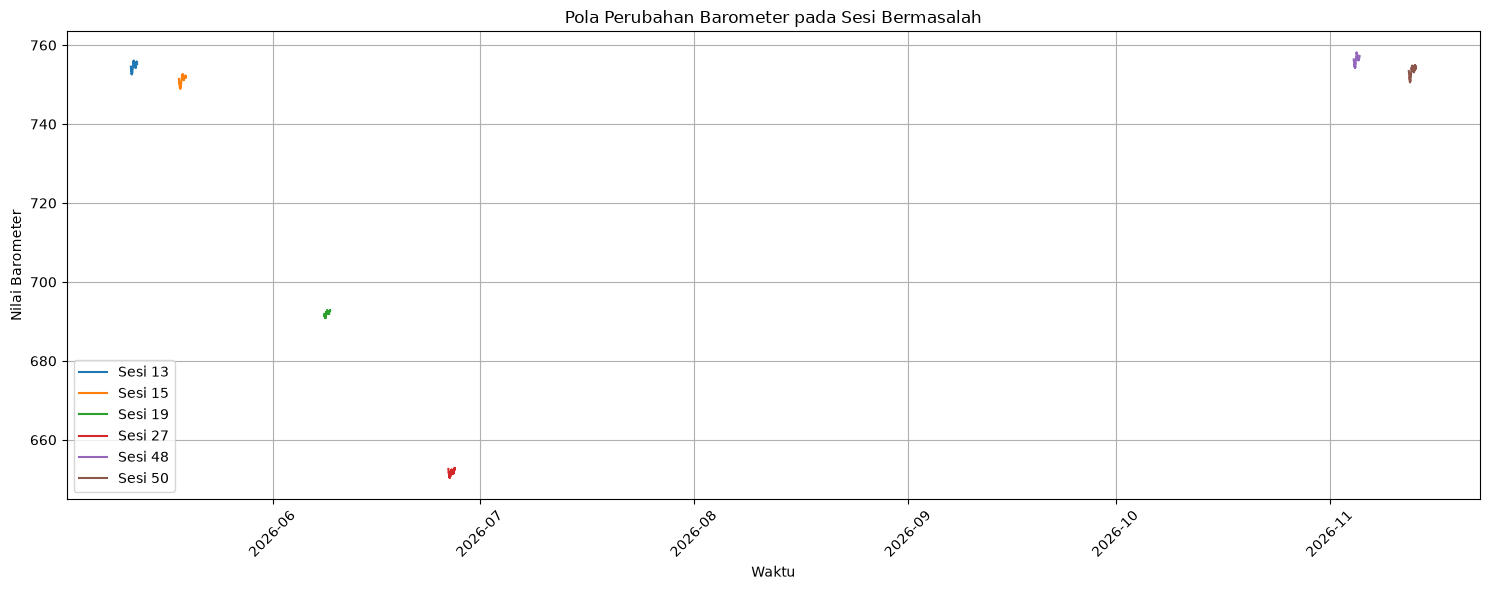

In [55]:
import matplotlib.pyplot as plt

sesi_diperiksa = [13, 15, 19, 27, 48, 50]

plt.figure(figsize=(15, 6))

for sesi in sesi_diperiksa:

    data_sesi = df_rule[
        df_rule["session_id"] == sesi
    ].sort_values("waktu_tercatat")

    plt.plot(
        data_sesi["waktu_tercatat"],
        data_sesi["barometer"],
        label=f"Sesi {sesi}"
    )

plt.title("Pola Perubahan Barometer pada Sesi Bermasalah")
plt.xlabel("Waktu")
plt.ylabel("Nilai Barometer")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [56]:
sesi_diperiksa = [13, 15, 19, 27, 48, 50]

print("===== PERUBAHAN BAROMETER PER SESI =====")

for sesi in sesi_diperiksa:

    data_sesi = df_rule[
        df_rule["session_id"] == sesi
    ].sort_values("waktu_tercatat")

    perubahan = data_sesi["barometer_delta"].dropna().abs()

    print(f"\nSesi {sesi}")
    print("Jumlah perubahan:", len(perubahan))
    print("Rata-rata perubahan:", round(perubahan.mean(), 4))
    print("Median perubahan:", round(perubahan.median(), 4))
    print("Perubahan maksimum:", round(perubahan.max(), 4))

===== PERUBAHAN BAROMETER PER SESI =====

Sesi 13
Jumlah perubahan: 1011
Rata-rata perubahan: 0.022
Median perubahan: 0.02
Perubahan maksimum: 0.1

Sesi 15
Jumlah perubahan: 1155
Rata-rata perubahan: 0.0204
Median perubahan: 0.02
Perubahan maksimum: 0.13

Sesi 19
Jumlah perubahan: 1075
Rata-rata perubahan: 0.019
Median perubahan: 0.02
Perubahan maksimum: 0.13

Sesi 27
Jumlah perubahan: 1217
Rata-rata perubahan: 0.0191
Median perubahan: 0.02
Perubahan maksimum: 0.09

Sesi 48
Jumlah perubahan: 1115
Rata-rata perubahan: 0.022
Median perubahan: 0.02
Perubahan maksimum: 0.13

Sesi 50
Jumlah perubahan: 1238
Rata-rata perubahan: 0.0218
Median perubahan: 0.02
Perubahan maksimum: 0.56


In [57]:
data_sesi_50 = df_rule[
    df_rule["session_id"] == 50
].copy()

data_sesi_50["abs_delta"] = (
    data_sesi_50["barometer_delta"].abs()
)

perubahan_terbesar = data_sesi_50.sort_values(
    "abs_delta",
    ascending=False
)

print("===== 10 PERUBAHAN BAROMETER TERBESAR SESI 50 =====")

display(
    perubahan_terbesar[
        [
            "waktu_tercatat",
            "barometer",
            "barometer_delta",
            "gap_sec"
        ]
    ].head(10)
)

===== 10 PERUBAHAN BAROMETER TERBESAR SESI 50 =====


,waktu_tercatat,barometer,barometer_delta,gap_sec
37418,2026-11-12 18:27:24,752.86,0.56,3153.0
37375,2026-11-12 16:49:33,752.00,0.12,142.0
37170,2026-11-12 12:46:47,751.67,-0.10,64.0
37193,2026-11-12 13:13:04,751.31,-0.09,64.0
37059,2026-11-12 10:43:09,753.14,-0.09,297.0
37338,2026-11-12 16:08:37,751.24,0.09,63.0
37357,2026-11-12 16:28:57,751.60,0.09,64.0
37191,2026-11-12 13:10:57,751.40,-0.09,64.0
37535,2026-11-12 20:49:09,754.54,0.09,65.0
37272,2026-11-12 14:56:21,750.68,0.09,152.0


In [58]:
data_sesi_50 = df_rule[
    df_rule["session_id"] == 50
].sort_values("waktu_tercatat").reset_index(drop=True)

posisi = data_sesi_50[
    data_sesi_50["waktu_tercatat"] ==
    pd.Timestamp("2026-11-12 18:27:24")
].index[0]

print("===== DATA SEKITAR PERUBAHAN TERBESAR =====")

display(
    data_sesi_50.iloc[
        max(0, posisi - 3):posisi + 4
    ][
        [
            "waktu_tercatat",
            "barometer",
            "barometer_delta",
            "gap_sec",
            "gap_panjang_flag"
        ]
    ]
)

===== DATA SEKITAR PERUBAHAN TERBESAR =====


,waktu_tercatat,barometer,barometer_delta,gap_sec,gap_panjang_flag
373,2026-11-12 17:32:44,752.27,0.01,64.0,0
374,2026-11-12 17:33:48,752.30,0.03,64.0,0
375,2026-11-12 17:34:51,752.30,0.00,63.0,0
376,2026-11-12 18:27:24,752.86,0.56,3153.0,1
377,2026-11-12 18:28:27,752.84,-0.02,63.0,0
378,2026-11-12 18:29:34,752.89,0.05,67.0,0
379,2026-11-12 18:30:38,752.93,0.04,64.0,0


In [59]:
sensor_list = [
    "suhu",
    "kelembaban",
    "pm10",
    "pm25",
    "barometer"
]

data_train = df_rule[
    df_rule["session_id"] <= 41
]

data_test = df_rule[
    df_rule["session_id"] >= 42
]

hasil_iqr_sensor = []

for sensor in sensor_list:

    Q1 = data_train[sensor].quantile(0.25)
    Q3 = data_train[sensor].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - (1.5 * IQR)
    batas_atas = Q3 + (1.5 * IQR)

    jumlah_anomali = (
        (data_test[sensor] < batas_bawah) |
        (data_test[sensor] > batas_atas)
    ).sum()

    hasil_iqr_sensor.append({
        "sensor": sensor,
        "batas_bawah": round(batas_bawah, 2),
        "batas_atas": round(batas_atas, 2),
        "jumlah_di_luar_iqr": jumlah_anomali,
        "persentase": round(
            jumlah_anomali / len(data_test) * 100, 2
        )
    })

df_hasil_iqr = pd.DataFrame(hasil_iqr_sensor)

print("===== HASIL IQR SETIAP SENSOR PADA DATA TESTING =====")

display(df_hasil_iqr)

===== HASIL IQR SETIAP SENSOR PADA DATA TESTING =====


,sensor,batas_bawah,batas_atas,jumlah_di_luar_iqr,persentase
0,suhu,15.04,38.48,612,5.36
1,kelembaban,20.50,96.50,0,0.00
2,pm10,-17.00,79.00,23,0.20
3,pm25,-5.00,35.00,116,1.02
4,barometer,694.28,708.32,2353,20.61


In [60]:
sensor_list = [
    "suhu",
    "kelembaban",
    "pm10",
    "pm25",
    "barometer"
]

data_train = df_rule[
    df_rule["session_id"] <= 41
]

data_test = df_hybrid.copy()

hasil_flags = pd.DataFrame(index=data_test.index)

for sensor in sensor_list:

    Q1 = data_train[sensor].quantile(0.25)
    Q3 = data_train[sensor].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - (1.5 * IQR)
    batas_atas = Q3 + (1.5 * IQR)

    hasil_flags[sensor] = (
        (data_test[sensor] < batas_bawah) |
        (data_test[sensor] > batas_atas)
    )

hasil_flags["jumlah_sensor_di_luar_iqr"] = (
    hasil_flags[sensor_list].sum(axis=1)
)

hasil_flags["kombinasi_sensor"] = hasil_flags.apply(
    lambda row: " + ".join(
        sensor for sensor in sensor_list
        if row[sensor]
    ) if row["jumlah_sensor_di_luar_iqr"] > 0 else "Normal",
    axis=1
)

print("===== KOMBINASI SENSOR DI LUAR IQR =====")

display(
    hasil_flags["kombinasi_sensor"]
    .value_counts()
    .rename_axis("kombinasi_sensor")
    .reset_index(name="jumlah_data")
)

print("\n===== PERBANDINGAN DENGAN UNUSUAL VALUE =====")

print(
    "Unusual Value saat ini:",
    int(data_test["unusual_value"].sum())
)

print(
    "Data dengan minimal satu sensor di luar IQR:",
    int((hasil_flags["jumlah_sensor_di_luar_iqr"] > 0).sum())
)

===== KOMBINASI SENSOR DI LUAR IQR =====


,kombinasi_sensor,jumlah_data
0,Normal,8653
1,barometer,2035
2,suhu + barometer,318
3,suhu,293
4,pm25,93
5,pm10 + pm25,22
6,suhu + pm10 + pm25,1



===== PERBANDINGAN DENGAN UNUSUAL VALUE =====
Unusual Value saat ini: 2598
Data dengan minimal satu sensor di luar IQR: 2762


In [61]:
sensor_tanpa_barometer = [
    "suhu",
    "kelembaban",
    "pm10",
    "pm25"
]

data_train = df_rule[
    df_rule["session_id"] <= 41
]

data_test = df_hybrid.copy()

flags_tanpa_barometer = pd.DataFrame(
    index=data_test.index
)

for sensor in sensor_tanpa_barometer:

    Q1 = data_train[sensor].quantile(0.25)
    Q3 = data_train[sensor].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - (1.5 * IQR)
    batas_atas = Q3 + (1.5 * IQR)

    flags_tanpa_barometer[sensor] = (
        (data_test[sensor] < batas_bawah) |
        (data_test[sensor] > batas_atas)
    )

flags_tanpa_barometer["unusual_tanpa_barometer"] = (
    flags_tanpa_barometer.any(axis=1)
)

print("===== SIMULASI UNUSUAL VALUE TANPA BAROMETER =====")

print(
    flags_tanpa_barometer[
        "unusual_tanpa_barometer"
    ].value_counts()
)

print("\n===== PERBANDINGAN =====")

print(
    "Unusual Value saat ini:",
    int(data_test["unusual_value"].sum())
)

print(
    "Unusual tanpa barometer:",
    int(flags_tanpa_barometer[
        "unusual_tanpa_barometer"
    ].sum())
)

===== SIMULASI UNUSUAL VALUE TANPA BAROMETER =====
unusual_tanpa_barometer
False    10688
True       727
Name: count, dtype: int64

===== PERBANDINGAN =====
Unusual Value saat ini: 2598
Unusual tanpa barometer: 727


In [62]:
perbandingan_unusual = pd.DataFrame({
    "unusual_lama": data_test["unusual_value"].astype(bool),
    "unusual_tanpa_barometer":
        flags_tanpa_barometer[
            "unusual_tanpa_barometer"
        ].astype(bool)
})

print("===== PERBANDINGAN UNUSUAL VALUE =====")

display(
    pd.crosstab(
        perbandingan_unusual["unusual_lama"],
        perbandingan_unusual["unusual_tanpa_barometer"],
        rownames=["Rule-Based saat ini"],
        colnames=["Simulasi tanpa barometer"]
    )
)

print("\n===== KATEGORI PERBANDINGAN =====")

print(
    "Terdeteksi keduanya:",
    int((
        perbandingan_unusual["unusual_lama"] &
        perbandingan_unusual["unusual_tanpa_barometer"]
    ).sum())
)

print(
    "Hanya Rule-Based saat ini:",
    int((
        perbandingan_unusual["unusual_lama"] &
        ~perbandingan_unusual["unusual_tanpa_barometer"]
    ).sum())
)

print(
    "Hanya simulasi tanpa barometer:",
    int((
        ~perbandingan_unusual["unusual_lama"] &
        perbandingan_unusual["unusual_tanpa_barometer"]
    ).sum())
)

===== PERBANDINGAN UNUSUAL VALUE =====


Simulasi tanpa barometer,False,True
Rule-Based saat ini,,
False,8653,164
True,2035,563



===== KATEGORI PERBANDINGAN =====
Terdeteksi keduanya: 563
Hanya Rule-Based saat ini: 2035
Hanya simulasi tanpa barometer: 164


In [63]:
print("===== SENSOR DI LUAR IQR PADA KEDUA METODE =====")

data_keduanya = perbandingan_unusual[
    perbandingan_unusual["unusual_lama"] &
    perbandingan_unusual["unusual_tanpa_barometer"]
].index

display(
    flags_tanpa_barometer.loc[data_keduanya, [
        "suhu",
        "kelembaban",
        "pm10",
        "pm25"
    ]].sum().sort_values(ascending=False)
)

===== SENSOR DI LUAR IQR PADA KEDUA METODE =====


suhu          476
pm25           88
pm10           23
kelembaban      0
dtype: int64

In [64]:
print("===== DISTRIBUSI SUHU DI LUAR IQR PER SESI =====")

data_suhu_anomali = data_test.loc[
    flags_tanpa_barometer["suhu"]
].copy()

hasil_suhu_per_sesi = (
    data_suhu_anomali
    .groupby("session_id")
    .size()
    .reset_index(name="jumlah_anomali_suhu")
    .sort_values(
        by="jumlah_anomali_suhu",
        ascending=False
    )
)

display(hasil_suhu_per_sesi)

print("\nTotal data suhu di luar IQR:",
      len(data_suhu_anomali))

===== DISTRIBUSI SUHU DI LUAR IQR PER SESI =====


,session_id,jumlah_anomali_suhu
3,48,175
5,50,143
2,44,101
4,49,100
1,43,62
0,42,31



Total data suhu di luar IQR: 612


In [65]:
print("===== STATISTIK SUHU PER SESI TESTING =====")

sesi_suhu = [42, 43, 44, 48, 49, 50]

display(
    data_test[
        data_test["session_id"].isin(sesi_suhu)
    ]
    .groupby("session_id")["suhu"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max",
        "std"
    ])
    .round(2)
)

print("\n===== STATISTIK SUHU DATA TRAINING =====")

display(
    data_train["suhu"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max",
        "std"
    ])
    .round(2)
)

===== STATISTIK SUHU PER SESI TESTING =====


,count,mean,median,min,max,std
session_id,,,,,,
42,1150,27.69,24.33,21.55,39.32,6.04
43,1214,27.82,26.02,22.24,40.02,4.99
44,1287,29.16,27.61,22.34,41.61,5.48
48,1115,32.16,30.39,28.30,41.11,3.91
49,1271,28.16,26.61,21.45,44.09,5.88
50,1238,31.26,29.59,26.12,42.50,4.71



===== STATISTIK SUHU DATA TRAINING =====


count     27116.00
mean         26.93
median       25.92
min          13.80
max          44.78
std           4.86
Name: suhu, dtype: float64

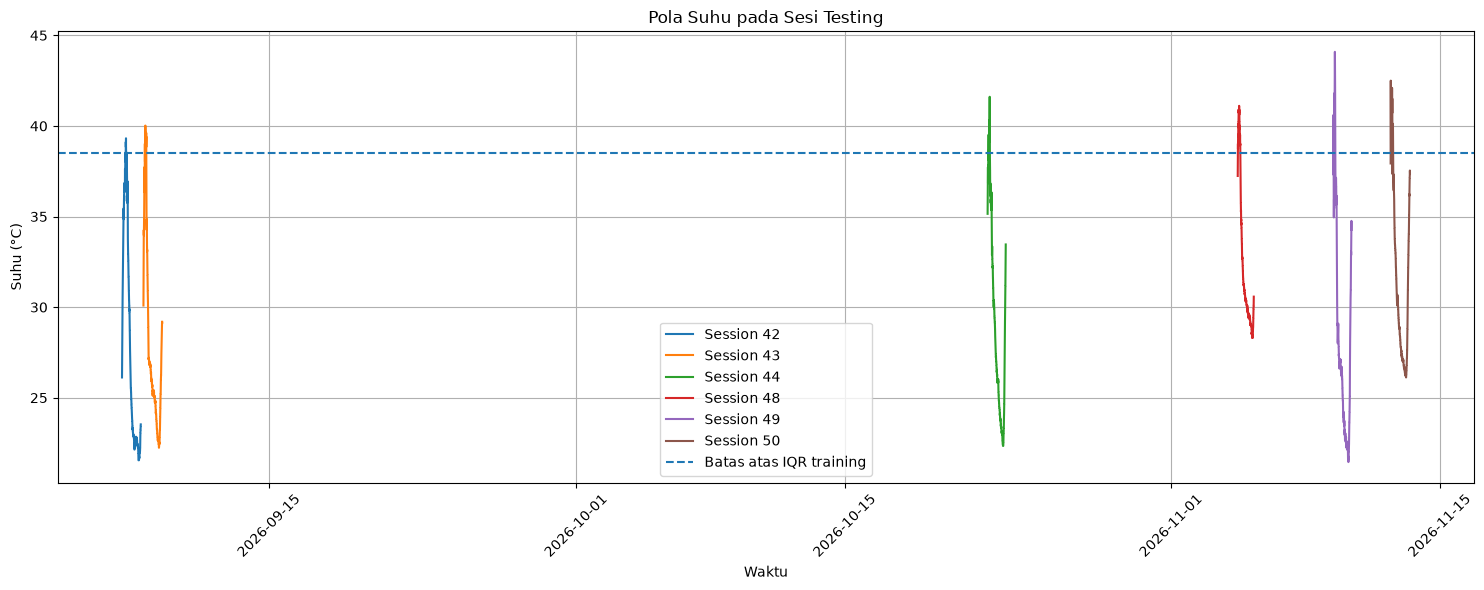

In [66]:
import matplotlib.pyplot as plt

sesi_suhu = [42, 43, 44, 48, 49, 50]

data_plot = data_test[
    data_test["session_id"].isin(sesi_suhu)
].copy()

plt.figure(figsize=(15, 6))

for sesi in sesi_suhu:
    data_sesi = data_plot[
        data_plot["session_id"] == sesi
    ].sort_values("waktu_tercatat")

    plt.plot(
        data_sesi["waktu_tercatat"],
        data_sesi["suhu"],
        label=f"Session {sesi}"
    )

plt.axhline(
    data_train["suhu"].quantile(0.75) +
    1.5 * (
        data_train["suhu"].quantile(0.75) -
        data_train["suhu"].quantile(0.25)
    ),
    linestyle="--",
    label="Batas atas IQR training"
)

plt.title("Pola Suhu pada Sesi Testing")
plt.xlabel("Waktu")
plt.ylabel("Suhu (°C)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [67]:
Q1 = data_train["suhu"].quantile(0.25)
Q3 = data_train["suhu"].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - (1.5 * IQR)
batas_atas = Q3 + (1.5 * IQR)

data_suhu = data_test.copy()

data_suhu["suhu_di_bawah_IQR"] = (
    data_suhu["suhu"] < batas_bawah
)

data_suhu["suhu_di_atas_IQR"] = (
    data_suhu["suhu"] > batas_atas
)

print("Batas bawah:", round(batas_bawah, 2))
print("Batas atas:", round(batas_atas, 2))

print("\n===== HASIL SUHU DI LUAR IQR =====")

print(
    "Di bawah batas IQR:",
    data_suhu["suhu_di_bawah_IQR"].sum()
)

print(
    "Di atas batas IQR:",
    data_suhu["suhu_di_atas_IQR"].sum()
)

print(
    "Total:",
    (
        data_suhu["suhu_di_bawah_IQR"].sum()
        + data_suhu["suhu_di_atas_IQR"].sum()
    )
)

Batas bawah: 15.04
Batas atas: 38.48

===== HASIL SUHU DI LUAR IQR =====
Di bawah batas IQR: 0
Di atas batas IQR: 612
Total: 612


In [68]:
print("===== PERSENTASE ANOMALI SUHU PER SESI =====")

ringkasan_suhu = data_suhu.groupby("session_id").agg(
    total_data=("suhu", "count"),
    jumlah_anomali=("suhu_di_atas_IQR", "sum")
)

ringkasan_suhu["persentase_anomali"] = (
    ringkasan_suhu["jumlah_anomali"] /
    ringkasan_suhu["total_data"] * 100
)

display(
    ringkasan_suhu.sort_values(
        "persentase_anomali",
        ascending=False
    ).round(2)
)

===== PERSENTASE ANOMALI SUHU PER SESI =====


,total_data,jumlah_anomali,persentase_anomali
session_id,,,
48,1115,175,15.70
50,1238,143,11.55
49,1271,100,7.87
44,1287,101,7.85
43,1214,62,5.11
42,1150,31,2.70
45,1284,0,0.00
47,1273,0,0.00
46,1332,0,0.00


In [69]:
print("===== DETAIL SUHU ANOMALI PER SESI =====")

detail_anomali_suhu = (
    data_suhu[data_suhu["suhu_di_atas_IQR"]]
    .groupby("session_id")
    .agg(
        jumlah_anomali=("suhu", "count"),
        rata_rata_suhu=("suhu", "mean"),
        suhu_tertinggi=("suhu", "max"),
        suhu_terendah=("suhu", "min"),
        waktu_awal=("waktu_tercatat", "min"),
        waktu_akhir=("waktu_tercatat", "max")
    )
    .round(2)
    .sort_values("jumlah_anomali", ascending=False)
)

display(detail_anomali_suhu)

===== DETAIL SUHU ANOMALI PER SESI =====


C:\Users\user\AppData\Local\Temp\ipykernel_5872\3198949188.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


,jumlah_anomali,rata_rata_suhu,suhu_tertinggi,suhu_terendah,waktu_awal,waktu_akhir
session_id,,,,,,
48,175,39.95,41.11,38.53,2026-11-04 11:16:54,2026-11-04 14:23:53
50,143,40.18,42.50,38.53,2026-11-12 10:22:20,2026-11-12 13:28:50
44,101,39.62,41.61,38.53,2026-10-22 11:17:25,2026-10-22 13:12:18
49,100,41.22,44.09,38.53,2026-11-09 10:33:00,2026-11-09 13:10:45
43,62,39.12,40.02,38.53,2026-09-08 12:25:37,2026-09-08 14:12:22
42,31,38.82,39.32,38.53,2026-09-07 12:22:42,2026-09-07 13:29:23


In [70]:
print("===== DISTRIBUSI ANOMALI SUHU PER 10 MENIT =====")

data_anomali_10menit = data_suhu[
    data_suhu["suhu_di_atas_IQR"]
].copy()

data_anomali_10menit["interval_10_menit"] = (
    data_anomali_10menit["waktu_tercatat"].dt.floor("10min")
)

hasil_interval_suhu = (
    data_anomali_10menit
    .groupby(["session_id", "interval_10_menit"])
    .size()
    .reset_index(name="jumlah_anomali")
)

hasil_interval_suhu = hasil_interval_suhu.sort_values(
    ["session_id", "interval_10_menit"]
)

display(hasil_interval_suhu)

===== DISTRIBUSI ANOMALI SUHU PER 10 MENIT =====


,session_id,interval_10_menit,jumlah_anomali
0,42,2026-09-07 12:20:00,1
1,42,2026-09-07 12:30:00,8
2,42,2026-09-07 12:40:00,9
3,42,2026-09-07 12:50:00,9
4,42,2026-09-07 13:00:00,3
...,...,...,...
76,50,2026-11-12 12:30:00,6
77,50,2026-11-12 12:50:00,8
78,50,2026-11-12 13:00:00,5
79,50,2026-11-12 13:10:00,10


In [71]:
print("===== INTERVAL ANOMALI SUHU TERBANYAK PER SESI =====")

idx_terbanyak = (
    hasil_interval_suhu
    .groupby("session_id")["jumlah_anomali"]
    .idxmax()
)

interval_terbanyak = (
    hasil_interval_suhu.loc[idx_terbanyak]
    .sort_values("session_id")
    .reset_index(drop=True)
)

display(interval_terbanyak)

print("\n===== RINGKASAN INTERVAL =====")

ringkasan_interval = (
    hasil_interval_suhu
    .groupby("session_id")
    .agg(
        total_anomali=("jumlah_anomali", "sum"),
        jumlah_interval=("jumlah_anomali", "count"),
        rata_rata_per_interval=("jumlah_anomali", "mean"),
        maksimum_per_interval=("jumlah_anomali", "max")
    )
    .round(2)
)

display(ringkasan_interval)

===== INTERVAL ANOMALI SUHU TERBANYAK PER SESI =====


,session_id,interval_10_menit,jumlah_anomali
0,42,2026-09-07 12:40:00,9
1,43,2026-09-08 12:50:00,10
2,44,2026-10-22 11:30:00,10
3,48,2026-11-04 11:20:00,10
4,49,2026-11-09 12:10:00,10
5,50,2026-11-12 11:10:00,10



===== RINGKASAN INTERVAL =====


,total_anomali,jumlah_interval,rata_rata_per_interval,maksimum_per_interval
session_id,,,,
42,31,6,5.17,9
43,62,11,5.64,10
44,101,13,7.77,10
48,175,20,8.75,10
49,100,13,7.69,10
50,143,18,7.94,10


In [72]:
print("===== DURASI ANOMALI SUHU BERTURUT-TURUT =====")

data_durasi = data_suhu.sort_values(
    ["session_id", "waktu_tercatat"]
).copy()

data_durasi["kelompok_anomali"] = (
    data_durasi["suhu_di_atas_IQR"]
    .ne(
        data_durasi.groupby("session_id")[
            "suhu_di_atas_IQR"
        ].shift()
    )
    .groupby(data_durasi["session_id"])
    .cumsum()
)

hasil_durasi = (
    data_durasi[data_durasi["suhu_di_atas_IQR"]]
    .groupby(["session_id", "kelompok_anomali"])
    .agg(
        jumlah_data=("suhu", "count"),
        waktu_mulai=("waktu_tercatat", "min"),
        waktu_selesai=("waktu_tercatat", "max"),
        suhu_rata_rata=("suhu", "mean"),
        suhu_maksimum=("suhu", "max")
    )
    .reset_index()
)

display(
    hasil_durasi.sort_values(
        ["session_id", "waktu_mulai"]
    ).round(2)
)

===== DURASI ANOMALI SUHU BERTURUT-TURUT =====


C:\Users\user\AppData\Local\Temp\ipykernel_5872\1402781392.py:34: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(2)


,session_id,kelompok_anomali,jumlah_data,waktu_mulai,waktu_selesai,suhu_rata_rata,suhu_maksimum
0,42,2,1,2026-09-07 12:22:42,2026-09-07 12:22:42,38.53,38.53
1,42,4,27,2026-09-07 12:31:43,2026-09-07 13:00:42,38.86,39.32
2,42,6,2,2026-09-07 13:06:24,2026-09-07 13:08:48,38.53,38.53
3,42,8,1,2026-09-07 13:29:23,2026-09-07 13:29:23,38.53,38.53
4,43,2,3,2026-09-08 12:25:37,2026-09-08 12:27:45,38.86,39.02
5,43,4,1,2026-09-08 12:30:56,2026-09-08 12:30:56,38.53,38.53
6,43,6,1,2026-09-08 12:37:20,2026-09-08 12:37:20,38.53,38.53
7,43,8,2,2026-09-08 12:39:29,2026-09-08 12:40:33,38.58,38.63
8,43,10,1,2026-09-08 12:42:40,2026-09-08 12:42:40,38.53,38.53
9,43,12,25,2026-09-08 12:47:00,2026-09-08 13:12:46,39.37,40.02


In [73]:
print("===== DISTRIBUSI ANOMALI PM2.5 PER SESI =====")

data_pm25 = data_test.copy()

Q1 = data_train["pm25"].quantile(0.25)
Q3 = data_train["pm25"].quantile(0.75)
IQR = Q3 - Q1

batas_bawah_pm25 = Q1 - (1.5 * IQR)
batas_atas_pm25 = Q3 + (1.5 * IQR)

data_pm25["pm25_di_luar_IQR"] = (
    (data_pm25["pm25"] < batas_bawah_pm25) |
    (data_pm25["pm25"] > batas_atas_pm25)
)

print("Batas bawah:", round(batas_bawah_pm25, 2))
print("Batas atas:", round(batas_atas_pm25, 2))

print(
    "Total PM2.5 di luar IQR:",
    int(data_pm25["pm25_di_luar_IQR"].sum())
)

display(
    data_pm25[data_pm25["pm25_di_luar_IQR"]]
    .groupby("session_id")
    .size()
    .reset_index(name="jumlah_anomali_pm25")
    .sort_values("jumlah_anomali_pm25", ascending=False)
)

===== DISTRIBUSI ANOMALI PM2.5 PER SESI =====
Batas bawah: -5.0
Batas atas: 35.0
Total PM2.5 di luar IQR: 116


,session_id,jumlah_anomali_pm25
4,46,92
1,43,11
2,44,6
6,49,3
5,47,2
0,42,1
3,45,1


In [74]:
print("===== KOLOM DATASET HYBRID =====")

for kolom in df_hybrid.columns:
    print(kolom)

print("\n===== 5 DATA PERTAMA =====")

display(df_hybrid.head())

===== KOLOM DATASET HYBRID =====
id_monitoring_udara
suhu
kelembaban
pm10
pm25
barometer
tvoc
waktu_tercatat
gap_sec
session_id
tvoc_duration
tvoc_change_flag
tvoc_delta
barometer_duration
barometer_change_flag
barometer_delta
pm10_duration
pm10_change_flag
pm10_delta
pm25_duration
pm25_change_flag
pm25_delta
gap_panjang_flag
awal_sesi_flag
pm10_delta_next
pm25_delta_next
kandidat_spike
stuck_value
unusual_value
rule_based_anomaly
kombinasi_deteksi
prediksi_if
skor_if
ai_anomaly
perbandingan_deteksi
kategori_hybrid
hybrid_anomaly

===== 5 DATA PERTAMA =====


,id_monitoring_udara,suhu,kelembaban,pm10,pm25,barometer,tvoc,waktu_tercatat,gap_sec,session_id,...,stuck_value,unusual_value,rule_based_anomaly,kombinasi_deteksi,prediksi_if,skor_if,ai_anomaly,perbandingan_deteksi,kategori_hybrid,hybrid_anomaly
0,191576,26.12,48,49.0,23.0,706.33,678.31,2026-09-07 07:50:24,427629.0,42,...,False,False,False,Normal,1,0.091059,False,Normal menurut keduanya,Normal,False
1,191577,26.91,46,51.0,24.0,706.29,678.31,2026-09-07 07:57:16,412.0,42,...,False,False,False,Normal,1,0.067781,False,Normal menurut keduanya,Normal,False
2,191578,27.31,46,52.0,23.0,706.30,678.31,2026-09-07 08:00:57,221.0,42,...,False,False,False,Normal,1,0.114104,False,Normal menurut keduanya,Normal,False
3,191579,27.41,46,48.0,23.0,706.27,678.31,2026-09-07 08:02:10,73.0,42,...,False,False,False,Normal,1,0.059778,False,Normal menurut keduanya,Normal,False
4,191580,27.51,45,48.0,23.0,706.26,678.31,2026-09-07 08:03:28,78.0,42,...,False,False,False,Normal,-1,-0.002042,True,AI saja,Anomali - AI saja,True


In [75]:
# Data training: session 1 sampai 41
df_train = df_rule[df_rule["session_id"].between(1, 41)].copy()

sensor_features = [
    "suhu",
    "kelembaban",
    "pm10",
    "pm25",
    "barometer"
]

# Menghitung batas IQR dari data training
hasil_iqr = []

for kolom in sensor_features:
    q1 = df_train[kolom].quantile(0.25)
    q3 = df_train[kolom].quantile(0.75)
    iqr = q3 - q1

    hasil_iqr.append({
        "sensor": kolom,
        "Q1": q1,
        "Q3": q3,
        "batas_bawah": q1 - (1.5 * iqr),
        "batas_atas": q3 + (1.5 * iqr)
    })

df_batas_iqr = pd.DataFrame(hasil_iqr)

print("===== BATAS NORMAL SENSOR BERDASARKAN DATA TRAINING =====")
display(df_batas_iqr.round(2))

===== BATAS NORMAL SENSOR BERDASARKAN DATA TRAINING =====


,sensor,Q1,Q3,batas_bawah,batas_atas
0,suhu,23.83,29.69,15.04,38.48
1,kelembaban,49.00,68.00,20.50,96.50
2,pm10,19.00,43.00,-17.00,79.00
3,pm25,10.00,20.00,-5.00,35.00
4,barometer,699.55,703.06,694.28,708.32


In [76]:
# Mengambil data kandidat anomali
df_severity = df_hybrid[
    df_hybrid["hybrid_anomaly"] == True
].copy()

# Menghitung tingkat penyimpangan setiap sensor
for _, baris in df_batas_iqr.iterrows():
    sensor = baris["sensor"]
    batas_bawah = baris["batas_bawah"]
    batas_atas = baris["batas_atas"]

    df_severity[f"deviasi_{sensor}"] = (
        np.maximum(
            batas_bawah - df_severity[sensor],
            df_severity[sensor] - batas_atas
        ).clip(lower=0)
    ) / (batas_atas - batas_bawah)

# Menghitung jumlah sensor yang menyimpang
kolom_deviasi = [
    f"deviasi_{sensor}" for sensor in sensor_features
]

df_severity["jumlah_sensor_menyimpang"] = (
    df_severity[kolom_deviasi].gt(0).sum(axis=1)
)

# Mengambil penyimpangan terbesar
df_severity["skor_deviasi_sensor"] = (
    df_severity[kolom_deviasi].max(axis=1).clip(upper=1) * 100
)

print("===== HASIL PENYIMPANGAN SENSOR =====")
display(
    df_severity[
        sensor_features
        + kolom_deviasi
        + ["jumlah_sensor_menyimpang", "skor_deviasi_sensor"]
    ].head(10).round(3)
)

print("\nJumlah kandidat anomali:", len(df_severity))


===== HASIL PENYIMPANGAN SENSOR =====


,suhu,kelembaban,pm10,pm25,barometer,deviasi_suhu,deviasi_kelembaban,deviasi_pm10,deviasi_pm25,deviasi_barometer,jumlah_sensor_menyimpang,skor_deviasi_sensor
4,27.51,45,48.0,23.0,706.26,0.0,0.0,0.0,0.0,0.0,0,0.0
5,27.70,45,48.0,23.0,706.30,0.0,0.0,0.0,0.0,0.0,0,0.0
11,28.70,43,29.0,16.0,706.24,0.0,0.0,0.0,0.0,0.0,0,0.0
12,28.80,42,31.0,16.0,706.24,0.0,0.0,0.0,0.0,0.0,0,0.0
15,29.09,42,24.0,12.0,706.27,0.0,0.0,0.0,0.0,0.0,0,0.0
23,30.19,40,24.0,12.0,706.21,0.0,0.0,0.0,0.0,0.0,0,0.0
34,31.58,36,18.0,10.0,706.19,0.0,0.0,0.0,0.0,0.0,0,0.0
58,33.36,35,22.0,11.0,706.12,0.0,0.0,0.0,0.0,0.0,0,0.0
66,34.06,34,20.0,11.0,706.02,0.0,0.0,0.0,0.0,0.0,0,0.0
77,34.56,32,20.0,11.0,705.96,0.0,0.0,0.0,0.0,0.0,0,0.0



Jumlah kandidat anomali: 3403


In [77]:
print("===== DISTRIBUSI JARAK WAKTU DATA =====")

display(
    df_hybrid["gap_sec"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame()
    .round(2)
)

print("\n===== JUMLAH JEDA WAKTU =====")

print("Jeda lebih dari 5 menit:",
      (df_hybrid["gap_sec"] > 300).sum())

print("Jeda lebih dari 10 menit:",
      (df_hybrid["gap_sec"] > 600).sum())

print("Jeda lebih dari 30 menit:",
      (df_hybrid["gap_sec"] > 1800).sum())

===== DISTRIBUSI JARAK WAKTU DATA =====


,gap_sec
count,11415.00
mean,568.85
std,35512.87
min,13.00
25%,63.00
50%,64.00
75%,65.00
90%,66.00
95%,68.00
99%,144.00



===== JUMLAH JEDA WAKTU =====
Jeda lebih dari 5 menit: 18
Jeda lebih dari 10 menit: 12
Jeda lebih dari 30 menit: 12


In [78]:
# Mengurutkan data berdasarkan sesi dan waktu
df_severity = df_severity.sort_values(
    ["session_id", "waktu_tercatat"]
).copy()

# Menandai kelompok anomali yang berurutan
df_severity["kelompok_anomali"] = (
    (
        (~df_severity["hybrid_anomaly"])
        .groupby(df_severity["session_id"])
        .cumsum()
    )
)

# Menghitung jumlah data anomali berurutan
df_severity["jumlah_berurutan"] = (
    df_severity.groupby(
        ["session_id", "kelompok_anomali"]
    )["hybrid_anomaly"].transform("size")
)

# Perkiraan durasi berdasarkan interval normal 64 detik
df_severity["durasi_anomali_detik"] = (
    df_severity["jumlah_berurutan"] * 64
)

print("===== DISTRIBUSI DURASI ANOMALI =====")

display(
    df_severity["durasi_anomali_detik"]
    .describe()
    .to_frame()
    .round(2)
)

print("\n===== 10 DATA DENGAN DURASI TERBESAR =====")

display(
    df_severity[
        [
            "session_id",
            "waktu_tercatat",
            "jumlah_berurutan",
            "durasi_anomali_detik"
        ]
    ]
    .sort_values("durasi_anomali_detik", ascending=False)
    .head(10)
)

===== DISTRIBUSI DURASI ANOMALI =====


,durasi_anomali_detik
count,3403.00
mean,55315.01
std,30432.75
min,320.00
25%,13056.00
50%,71360.00
75%,79232.00
max,79232.00



===== 10 DATA DENGAN DURASI TERBESAR =====


,session_id,waktu_tercatat,jumlah_berurutan,durasi_anomali_detik
11153,50,2026-11-13 10:20:31,1238,79232
10118,50,2026-11-12 13:58:50,1238,79232
10119,50,2026-11-12 13:59:54,1238,79232
10120,50,2026-11-12 14:00:59,1238,79232
10121,50,2026-11-12 14:02:02,1238,79232
10122,50,2026-11-12 14:03:06,1238,79232
10123,50,2026-11-12 14:04:14,1238,79232
10124,50,2026-11-12 14:05:18,1238,79232
10125,50,2026-11-12 14:06:21,1238,79232
10126,50,2026-11-12 14:07:26,1238,79232


In [79]:
# Menggunakan seluruh data, bukan hanya kandidat anomali
df_durasi = df_hybrid.copy()

df_durasi["waktu_tercatat"] = pd.to_datetime(
    df_durasi["waktu_tercatat"]
)

df_durasi = df_durasi.sort_values(
    ["session_id", "waktu_tercatat"]
).copy()

# Menghitung jarak waktu antar-data dalam setiap sesi
df_durasi["interval_detik"] = (
    df_durasi.groupby("session_id")["waktu_tercatat"]
    .diff()
    .dt.total_seconds()
)

# Membuat kelompok baru ketika:
# 1. Status anomali berubah
# 2. Jeda waktu lebih dari 5 menit
status_berubah = (
    df_durasi.groupby("session_id")["hybrid_anomaly"]
    .transform(lambda x: x.ne(x.shift()))
)

jeda_panjang = df_durasi["interval_detik"] > 300

df_durasi["kelompok"] = (
    status_berubah | jeda_panjang
).groupby(df_durasi["session_id"]).cumsum()

# Mengambil hanya kelompok anomali
data_anomali_berurutan = df_durasi[
    df_durasi["hybrid_anomaly"] == True
].copy()

# Menghitung durasi setiap kelompok
ringkasan_durasi = (
    data_anomali_berurutan
    .groupby(["session_id", "kelompok"])
    .agg(
        waktu_mulai=("waktu_tercatat", "min"),
        waktu_selesai=("waktu_tercatat", "max"),
        jumlah_data=("hybrid_anomaly", "size")
    )
    .reset_index()
)

# Durasi aktual dari waktu awal sampai akhir
# Ditambah satu interval pengamatan sekitar 64 detik
ringkasan_durasi["durasi_detik"] = (
    ringkasan_durasi["waktu_selesai"]
    - ringkasan_durasi["waktu_mulai"]
).dt.total_seconds() + 64

print("===== DISTRIBUSI DURASI ANOMALI =====")

display(
    ringkasan_durasi["durasi_detik"]
    .describe()
    .to_frame()
    .round(2)
)

print("\n===== 10 KELOMPOK ANOMALI TERLAMA =====")

display(
    ringkasan_durasi
    .sort_values("durasi_detik", ascending=False)
    .head(10)
)

===== DISTRIBUSI DURASI ANOMALI =====


,durasi_detik
count,622.00
mean,359.31
std,3611.37
min,64.00
25%,64.00
50%,64.00
75%,127.00
max,72329.00



===== 10 KELOMPOK ANOMALI TERLAMA =====


,session_id,kelompok,waktu_mulai,waktu_selesai,jumlah_data,durasi_detik
551,48,1,2026-11-04 11:08:27,2026-11-05 07:12:52,1115,72329.0
608,50,3,2026-11-12 21:48:57,2026-11-13 10:31:09,702,45796.0
606,50,1,2026-11-12 10:21:17,2026-11-12 17:34:51,376,26078.0
607,50,2,2026-11-12 18:27:24,2026-11-12 21:42:36,160,11776.0
564,49,26,2026-11-09 12:11:16,2026-11-09 13:07:35,54,3443.0
230,44,48,2026-10-22 12:34:19,2026-10-22 13:09:08,34,2153.0
229,44,46,2026-10-22 12:02:43,2026-10-22 12:31:10,28,1771.0
433,46,172,2026-10-29 04:57:28,2026-10-29 05:21:39,24,1515.0
563,49,24,2026-11-09 11:45:31,2026-11-09 12:06:59,20,1352.0
453,46,212,2026-10-29 07:33:12,2026-10-29 07:45:49,13,821.0


In [80]:
print("===== PERSENTIL DURASI ANOMALI =====")

display(
    ringkasan_durasi["durasi_detik"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame(name="durasi_detik")
)

print("\n===== RINGKASAN DURASI PER SESI =====")

display(
    ringkasan_durasi.groupby("session_id")
    .agg(
        jumlah_kelompok=("kelompok", "count"),
        total_data_anomali=("jumlah_data", "sum"),
        durasi_terpanjang=("durasi_detik", "max")
    )
    .sort_values("durasi_terpanjang", ascending=False)
)

===== PERSENTIL DURASI ANOMALI =====


,durasi_detik
0.50,64.00
0.75,127.00
0.90,190.00
0.95,250.80
0.99,1717.24



===== RINGKASAN DURASI PER SESI =====


,jumlah_kelompok,total_data_anomali,durasi_terpanjang
session_id,,,
48,1,1115,72329.0
50,3,1238,45796.0
49,54,152,3443.0
44,87,183,2153.0
46,114,204,1515.0
43,94,151,650.0
42,113,161,339.0
45,54,64,254.0
47,89,119,194.0


In [81]:
# Menggabungkan durasi kelompok ke setiap data anomali
df_severity = data_anomali_berurutan.merge(
    ringkasan_durasi[
        ["session_id", "kelompok", "durasi_detik"]
    ],
    on=["session_id", "kelompok"],
    how="left"
)

# Batas maksimal berdasarkan persentil ke-95
batas_durasi = ringkasan_durasi["durasi_detik"].quantile(0.95)

# Menghitung skor durasi 0-100
df_severity["skor_durasi"] = (
    df_severity["durasi_detik"] / batas_durasi * 100
).clip(upper=100)

print("Batas durasi maksimal:", round(batas_durasi, 2), "detik")

print("\n===== HASIL SKOR DURASI =====")

display(
    df_severity[
        [
            "session_id",
            "waktu_tercatat",
            "durasi_detik",
            "skor_durasi"
        ]
    ].head(10).round(2)
)

print("\n===== DISTRIBUSI SKOR DURASI =====")

display(
    df_severity["skor_durasi"]
    .describe()
    .to_frame()
    .round(2)
)

Batas durasi maksimal: 250.8 detik

===== HASIL SKOR DURASI =====


C:\Users\user\AppData\Local\Temp\ipykernel_5872\1831672541.py:30: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2)


,session_id,waktu_tercatat,durasi_detik,skor_durasi
0,42,2026-09-07 08:03:28,130.0,51.83
1,42,2026-09-07 08:04:34,130.0,51.83
2,42,2026-09-07 08:14:04,135.0,53.83
3,42,2026-09-07 08:15:15,135.0,53.83
4,42,2026-09-07 08:18:47,64.0,25.52
5,42,2026-09-07 08:32:11,64.0,25.52
6,42,2026-09-07 08:51:54,64.0,25.52
7,42,2026-09-07 09:20:01,64.0,25.52
8,42,2026-09-07 09:29:06,64.0,25.52
9,42,2026-09-07 09:41:38,131.0,52.23



===== DISTRIBUSI SKOR DURASI =====


,skor_durasi
count,3403.00
mean,86.47
std,26.63
min,25.52
25%,100.00
50%,100.00
75%,100.00
max,100.00


In [82]:
print("===== SKOR DURASI PER SESI =====")

display(
    df_severity.groupby("session_id")
    .agg(
        jumlah_data=("skor_durasi", "count"),
        rata_rata_skor=("skor_durasi", "mean"),
        median_skor=("skor_durasi", "median"),
        skor_maksimal=("skor_durasi", "max")
    )
    .round(2)
    .sort_values("rata_rata_skor", ascending=False)
)

===== SKOR DURASI PER SESI =====


,jumlah_data,rata_rata_skor,median_skor,skor_maksimal
session_id,,,,
48,1115,100.00,100.00,100.00
50,1238,100.00,100.00,100.00
49,152,74.06,100.00,100.00
44,183,64.98,51.04,100.00
46,204,58.80,50.64,100.00
43,151,55.34,50.64,100.00
42,161,46.91,51.04,100.00
47,119,42.00,25.52,77.35
45,64,36.48,25.52,100.00


In [83]:
# Menghitung kembali penyimpangan lima sensor
for _, baris in df_batas_iqr.iterrows():
    sensor = baris["sensor"]

    batas_bawah = baris["batas_bawah"]
    batas_atas = baris["batas_atas"]

    df_severity[f"deviasi_{sensor}"] = (
        (df_severity[sensor] < batas_bawah) |
        (df_severity[sensor] > batas_atas)
    )

# Menghitung jumlah sensor yang menyimpang
kolom_deviasi = [
    f"deviasi_{sensor}" for sensor in sensor_features
]

df_severity["jumlah_sensor_menyimpang"] = (
    df_severity[kolom_deviasi].sum(axis=1)
)

# Skor jumlah sensor: 0 sampai 100
df_severity["skor_jumlah_sensor"] = (
    df_severity["jumlah_sensor_menyimpang"] / 5 * 100
)

print("===== HASIL SKOR JUMLAH SENSOR =====")

display(
    df_severity[
        [
            "session_id",
            "jumlah_sensor_menyimpang",
            "skor_jumlah_sensor"
        ]
    ].head(15)
)

print("\n===== DISTRIBUSI JUMLAH SENSOR MENYIMPANG =====")

display(
    df_severity["jumlah_sensor_menyimpang"]
    .value_counts()
    .sort_index()
    .to_frame(name="jumlah_data")
)

===== HASIL SKOR JUMLAH SENSOR =====


,session_id,jumlah_sensor_menyimpang,skor_jumlah_sensor
0,42,0,0.0
1,42,0,0.0
2,42,0,0.0
3,42,0,0.0
4,42,0,0.0
5,42,0,0.0
6,42,0,0.0
7,42,0,0.0
8,42,0,0.0
9,42,0,0.0



===== DISTRIBUSI JUMLAH SENSOR MENYIMPANG =====


,jumlah_data
jumlah_sensor_menyimpang,
0,749
1,2313
2,340
3,1


In [84]:
# Menghitung kesesuaian deteksi Rule-Based dan AI

df_severity["skor_kesesuaian"] = np.where(
    (df_severity["rule_based_anomaly"] == True) &
    (df_severity["ai_anomaly"] == True),
    100,
    50
)

print("===== DISTRIBUSI KESESUAIAN DETEKSI =====")

display(
    df_severity["kategori_hybrid"]
    .value_counts()
    .to_frame(name="jumlah_data")
)

print("\n===== HASIL SKOR KESESUAIAN =====")

display(
    df_severity[
        [
            "kategori_hybrid",
            "rule_based_anomaly",
            "ai_anomaly",
            "skor_kesesuaian"
        ]
    ].head(15)
)

print("\n===== RINGKASAN SKOR KESESUAIAN =====")

display(
    df_severity["skor_kesesuaian"]
    .value_counts()
    .sort_index()
    .to_frame(name="jumlah_data")
)

===== DISTRIBUSI KESESUAIAN DETEKSI =====


,jumlah_data
kategori_hybrid,
Anomali - Rule-Based saja,1871
Anomali - AI saja,792
Anomali - Rule-Based + AI,740



===== HASIL SKOR KESESUAIAN =====


,kategori_hybrid,rule_based_anomaly,ai_anomaly,skor_kesesuaian
0,Anomali - AI saja,False,True,50
1,Anomali - AI saja,False,True,50
2,Anomali - AI saja,False,True,50
3,Anomali - AI saja,False,True,50
4,Anomali - AI saja,False,True,50
5,Anomali - AI saja,False,True,50
6,Anomali - AI saja,False,True,50
7,Anomali - AI saja,False,True,50
8,Anomali - AI saja,False,True,50
9,Anomali - AI saja,False,True,50



===== RINGKASAN SKOR KESESUAIAN =====


,jumlah_data
skor_kesesuaian,
50,2663
100,740


In [86]:
# Menghitung kembali deviasi masing-masing sensor

for _, baris in df_batas_iqr.iterrows():
    sensor = baris["sensor"]
    batas_bawah = baris["batas_bawah"]
    batas_atas = baris["batas_atas"]

    df_severity[f"deviasi_{sensor}"] = (
        np.maximum(
            batas_bawah - df_severity[sensor],
            df_severity[sensor] - batas_atas
        ).clip(lower=0)
    ) / (batas_atas - batas_bawah)

# Menghitung skor deviasi sensor
kolom_deviasi = [
    f"deviasi_{sensor}" for sensor in sensor_features
]

df_severity["skor_deviasi_sensor"] = (
    df_severity[kolom_deviasi]
    .max(axis=1)
    .clip(upper=1) * 100
)

print("Kolom skor deviasi sensor berhasil dibuat.")
display(
    df_severity[
        ["session_id", "skor_deviasi_sensor"]
    ].head(10).round(2)
)

Kolom skor deviasi sensor berhasil dibuat.


,session_id,skor_deviasi_sensor
0,42,0.0
1,42,0.0
2,42,0.0
3,42,0.0
4,42,0.0
5,42,0.0
6,42,0.0
7,42,0.0
8,42,0.0
9,42,0.0


In [87]:
# Menghitung skor akhir Severity Scoring

df_severity["skor_severity"] = (
    df_severity["skor_deviasi_sensor"] * 0.40 +
    df_severity["skor_durasi"] * 0.25 +
    df_severity["skor_jumlah_sensor"] * 0.20 +
    df_severity["skor_kesesuaian"] * 0.15
)

# Membuat kategori tingkat keparahan
df_severity["tingkat_severity"] = pd.cut(
    df_severity["skor_severity"],
    bins=[-1, 29, 59, 100],
    labels=["Rendah", "Sedang", "Tinggi"]
)

print("===== 10 HASIL SEVERITY SCORING =====")

display(
    df_severity[
        [
            "session_id",
            "waktu_tercatat",
            "skor_deviasi_sensor",
            "skor_durasi",
            "skor_jumlah_sensor",
            "skor_kesesuaian",
            "skor_severity",
            "tingkat_severity"
        ]
    ].head(10).round(2)
)

print("\n===== DISTRIBUSI TINGKAT SEVERITY =====")

display(
    df_severity["tingkat_severity"]
    .value_counts()
    .sort_index()
    .to_frame(name="jumlah_data")
)

===== 10 HASIL SEVERITY SCORING =====


C:\Users\user\AppData\Local\Temp\ipykernel_5872\2588106219.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2)


,session_id,waktu_tercatat,skor_deviasi_sensor,skor_durasi,skor_jumlah_sensor,skor_kesesuaian,skor_severity,tingkat_severity
0,42,2026-09-07 08:03:28,0.0,51.83,0.0,50,20.46,Rendah
1,42,2026-09-07 08:04:34,0.0,51.83,0.0,50,20.46,Rendah
2,42,2026-09-07 08:14:04,0.0,53.83,0.0,50,20.96,Rendah
3,42,2026-09-07 08:15:15,0.0,53.83,0.0,50,20.96,Rendah
4,42,2026-09-07 08:18:47,0.0,25.52,0.0,50,13.88,Rendah
5,42,2026-09-07 08:32:11,0.0,25.52,0.0,50,13.88,Rendah
6,42,2026-09-07 08:51:54,0.0,25.52,0.0,50,13.88,Rendah
7,42,2026-09-07 09:20:01,0.0,25.52,0.0,50,13.88,Rendah
8,42,2026-09-07 09:29:06,0.0,25.52,0.0,50,13.88,Rendah
9,42,2026-09-07 09:41:38,0.0,52.23,0.0,50,20.56,Rendah



===== DISTRIBUSI TINGKAT SEVERITY =====


,jumlah_data
tingkat_severity,
Rendah,732
Sedang,307
Tinggi,2364


In [88]:
print("===== DISTRIBUSI SEVERITY PER SESI =====")

display(
    pd.crosstab(
        df_severity["session_id"],
        df_severity["tingkat_severity"],
        margins=True
    )
)

print("\n===== RATA-RATA SKOR SEVERITY PER SESI =====")

display(
    df_severity.groupby("session_id")
    .agg(
        jumlah_data=("skor_severity", "count"),
        rata_rata=("skor_severity", "mean"),
        median=("skor_severity", "median"),
        minimum=("skor_severity", "min"),
        maksimum=("skor_severity", "max")
    )
    .round(2)
)

===== DISTRIBUSI SEVERITY PER SESI =====


tingkat_severity,Rendah,Sedang,Tinggi,All
session_id,,,,
42,146,15,0,161
43,105,40,6,151
44,97,86,0,183
45,60,4,0,64
46,126,74,4,204
47,118,1,0,119
48,0,0,1115,1115
49,64,87,1,152
50,0,0,1238,1238



===== RATA-RATA SKOR SEVERITY PER SESI =====


,jumlah_data,rata_rata,median,minimum,maksimum
session_id,,,,,
42,161,19.52,20.26,13.88,32.50
43,151,24.81,20.26,13.88,85.00
44,183,27.67,24.24,13.88,48.49
45,64,16.83,13.88,13.88,32.50
46,204,26.77,20.26,13.88,65.00
47,119,18.22,13.88,13.88,48.24
48,1115,79.13,76.50,76.50,88.00
49,152,32.37,38.19,13.88,75.00
50,1238,79.05,76.50,76.50,88.00


In [89]:
print("===== RATA-RATA KOMPONEN SEVERITY PER SESI =====")

display(
    df_severity.groupby("session_id")
    .agg(
        skor_deviasi=("skor_deviasi_sensor", "mean"),
        skor_durasi=("skor_durasi", "mean"),
        skor_jumlah_sensor=("skor_jumlah_sensor", "mean"),
        skor_kesesuaian=("skor_kesesuaian", "mean"),
        skor_akhir=("skor_severity", "mean")
    )
    .round(2)
)

===== RATA-RATA KOMPONEN SEVERITY PER SESI =====


,skor_deviasi,skor_durasi,skor_jumlah_sensor,skor_kesesuaian,skor_akhir
session_id,,,,,
42,0.10,46.91,1.24,50.00,19.52
43,3.27,55.34,6.62,55.63,24.81
44,2.72,64.98,9.51,56.28,27.67
45,0.08,36.48,0.31,50.78,16.83
46,3.95,58.80,8.53,58.58,26.77
47,0.15,42.00,0.50,50.42,18.22
48,100.00,100.00,23.14,63.36,79.13
49,7.69,74.06,11.45,56.58,32.37
50,100.00,100.00,22.31,63.93,79.05


In [90]:
# Simulasi bobot severity alternatif

df_severity["skor_severity_simulasi"] = (
    df_severity["skor_deviasi_sensor"] * 0.50 +
    df_severity["skor_durasi"] * 0.10 +
    df_severity["skor_jumlah_sensor"] * 0.25 +
    df_severity["skor_kesesuaian"] * 0.15
)

# Membandingkan skor berdasarkan sesi

display(
    df_severity.groupby("session_id")
    .agg(
        skor_sekarang=("skor_severity", "mean"),
        skor_simulasi=("skor_severity_simulasi", "mean")
    )
    .round(2)
)

print("\n===== DISTRIBUSI SKOR SIMULASI =====")

display(
    pd.cut(
        df_severity["skor_severity_simulasi"],
        bins=[-1, 29, 59, 100],
        labels=["Rendah", "Sedang", "Tinggi"]
    )
    .value_counts()
    .sort_index()
    .to_frame(name="jumlah_data")
)

,skor_sekarang,skor_simulasi
session_id,,
42,19.52,12.55
43,24.81,17.17
44,27.67,18.68
45,16.83,11.38
46,26.77,18.77
47,18.22,11.96
48,79.13,75.29
49,32.37,22.60
50,79.05,75.17



===== DISTRIBUSI SKOR SIMULASI =====


,jumlah_data
skor_severity_simulasi,
Rendah,927
Sedang,118
Tinggi,2358


In [91]:
print("===== RATA-RATA DEVIASI SENSOR SESI 48 DAN 50 =====")

kolom_deviasi = [
    f"deviasi_{sensor}" for sensor in sensor_features
]

display(
    df_severity[
        df_severity["session_id"].isin([48, 50])
    ]
    .groupby("session_id")[kolom_deviasi]
    .mean()
    .mul(100)
    .round(2)
)

===== RATA-RATA DEVIASI SENSOR SESI 48 DAN 50 =====


,deviasi_suhu,deviasi_kelembaban,deviasi_pm10,deviasi_pm25,deviasi_barometer
session_id,,,,,
48,0.99,0.0,0.0,0.0,341.62
50,0.84,0.0,0.0,0.0,320.71


In [92]:
# Menghitung deviasi sensor tanpa barometer

kolom_deviasi_tanpa_barometer = [
    "deviasi_suhu",
    "deviasi_kelembaban",
    "deviasi_pm10",
    "deviasi_pm25"
]

df_severity["skor_deviasi_tanpa_barometer"] = (
    df_severity[kolom_deviasi_tanpa_barometer]
    .max(axis=1)
    .clip(upper=1) * 100
)

# Menghitung skor severity simulasi tanpa deviasi barometer

df_severity["skor_severity_tanpa_barometer"] = (
    df_severity["skor_deviasi_tanpa_barometer"] * 0.40 +
    df_severity["skor_durasi"] * 0.25 +
    df_severity["skor_jumlah_sensor"] * 0.20 +
    df_severity["skor_kesesuaian"] * 0.15
)

# Membandingkan sesi 48 dan 50

display(
    df_severity[
        df_severity["session_id"].isin([48, 50])
    ]
    .groupby("session_id")
    .agg(
        skor_sebelumnya=("skor_severity", "mean"),
        skor_tanpa_barometer=(
            "skor_severity_tanpa_barometer", "mean"
        )
    )
    .round(2)
)

print("\n===== DISTRIBUSI SEVERITY TANPA DEVIASI BAROMETER =====")

kategori_simulasi = pd.cut(
    df_severity["skor_severity_tanpa_barometer"],
    bins=[-1, 29, 59, 100],
    labels=["Rendah", "Sedang", "Tinggi"]
)

display(
    kategori_simulasi.value_counts()
    .sort_index()
    .to_frame(name="jumlah_data")
)

,skor_sebelumnya,skor_tanpa_barometer
session_id,,
48,79.13,39.53
50,79.05,39.39



===== DISTRIBUSI SEVERITY TANPA DEVIASI BAROMETER =====


,jumlah_data
skor_severity_tanpa_barometer,
Rendah,732
Sedang,2660
Tinggi,11


In [93]:
print("===== PERBANDINGAN SEVERITY SEMUA SESI =====")

display(
    df_severity.groupby("session_id")
    .agg(
        skor_awal=("skor_severity", "mean"),
        skor_tanpa_barometer=(
            "skor_severity_tanpa_barometer", "mean"
        )
    )
    .round(2)
)

print("\n===== DISTRIBUSI KATEGORI TANPA BAROMETER =====")

display(
    df_severity.assign(
        kategori_tanpa_barometer=kategori_simulasi
    )
    .groupby(
        ["session_id", "kategori_tanpa_barometer"],
        observed=False
    )
    .size()
    .unstack(fill_value=0)
)

===== PERBANDINGAN SEVERITY SEMUA SESI =====


,skor_awal,skor_tanpa_barometer
session_id,,
42,19.52,19.52
43,24.81,24.81
44,27.67,27.67
45,16.83,16.83
46,26.77,26.77
47,18.22,18.22
48,79.13,39.53
49,32.37,32.37
50,79.05,39.39



===== DISTRIBUSI KATEGORI TANPA BAROMETER =====


kategori_tanpa_barometer,Rendah,Sedang,Tinggi
session_id,,,
42,146,15,0
43,105,40,6
44,97,86,0
45,60,4,0
46,126,74,4
47,118,1,0
48,0,1115,0
49,64,87,1
50,0,1238,0


In [94]:
# Membuat kategori severity alternatif

df_severity["tingkat_severity_final"] = pd.cut(
    df_severity["skor_severity_tanpa_barometer"],
    bins=[-1, 29, 59, 100],
    labels=["Rendah", "Sedang", "Tinggi"]
)

print("===== DISTRIBUSI SEVERITY ALTERNATIF =====")

display(
    df_severity["tingkat_severity_final"]
    .value_counts()
    .sort_index()
    .to_frame(name="jumlah_data")
)

print("\n===== RATA-RATA SEVERITY PER SESI =====")

display(
    df_severity.groupby("session_id")
    .agg(
        jumlah_data=("skor_severity_tanpa_barometer", "count"),
        rata_rata_skor=("skor_severity_tanpa_barometer", "mean"),
        kategori_rendah=(
            "tingkat_severity_final",
            lambda x: (x == "Rendah").sum()
        ),
        kategori_sedang=(
            "tingkat_severity_final",
            lambda x: (x == "Sedang").sum()
        ),
        kategori_tinggi=(
            "tingkat_severity_final",
            lambda x: (x == "Tinggi").sum()
        )
    )
    .round(2)
)

===== DISTRIBUSI SEVERITY ALTERNATIF =====


,jumlah_data
tingkat_severity_final,
Rendah,732
Sedang,2660
Tinggi,11



===== RATA-RATA SEVERITY PER SESI =====


,jumlah_data,rata_rata_skor,kategori_rendah,kategori_sedang,kategori_tinggi
session_id,,,,,
42,161,19.52,146,15,0
43,151,24.81,105,40,6
44,183,27.67,97,86,0
45,64,16.83,60,4,0
46,204,26.77,126,74,4
47,119,18.22,118,1,0
48,1115,39.53,0,1115,0
49,152,32.37,64,87,1
50,1238,39.39,0,1238,0


In [95]:
df_severity["tingkat_severity_final"] = pd.cut(
    df_severity["skor_severity_tanpa_barometer"],
    bins=[-1, 29, 59, 100],
    labels=["Rendah", "Sedang", "Tinggi"]
)

print("Distribusi Severity Final:")
print(df_severity["tingkat_severity_final"].value_counts())

print("\nRata-rata Severity Final:")
print(df_severity.groupby("session_id", observed=False)["skor_severity_tanpa_barometer"].mean().round(2))

Distribusi Severity Final:
tingkat_severity_final
Sedang    2660
Rendah     732
Tinggi      11
Name: count, dtype: int64

Rata-rata Severity Final:
session_id
42    19.52
43    24.81
44    27.67
45    16.83
46    26.77
47    18.22
48    39.53
49    32.37
50    39.39
51    16.43
52    16.16
Name: skor_severity_tanpa_barometer, dtype: float64


In [96]:
import os

output_path = "outputs/hasil_severity_scoring_4sensor.csv"

os.makedirs("outputs", exist_ok=True)

df_severity.to_csv(output_path, index=False)

print("Severity Scoring berhasil disimpan!")
print("Lokasi:", output_path)
print("Jumlah data:", len(df_severity))
print("Jumlah kolom:", len(df_severity.columns))

Severity Scoring berhasil disimpan!
Lokasi: outputs/hasil_severity_scoring_4sensor.csv
Jumlah data: 3403
Jumlah kolom: 56


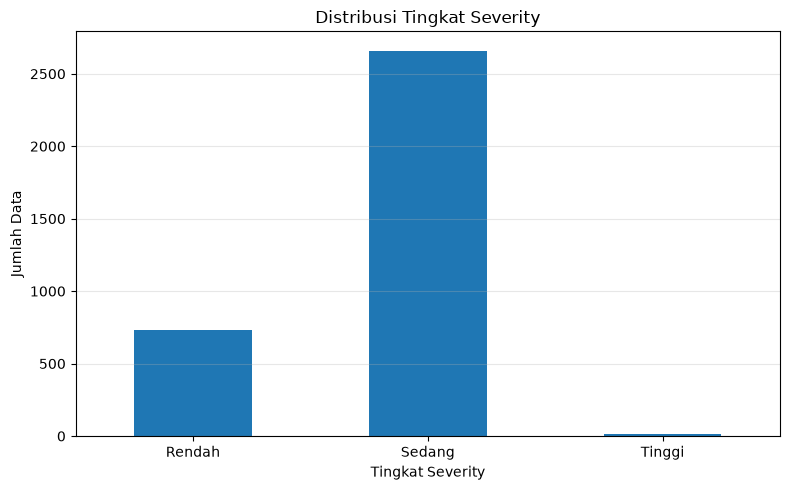

In [97]:
import matplotlib.pyplot as plt

jumlah_severity = df_severity["tingkat_severity_final"].value_counts().reindex(
    ["Rendah", "Sedang", "Tinggi"],
    fill_value=0
)

plt.figure(figsize=(8, 5))
jumlah_severity.plot(kind="bar")

plt.title("Distribusi Tingkat Severity")
plt.xlabel("Tingkat Severity")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

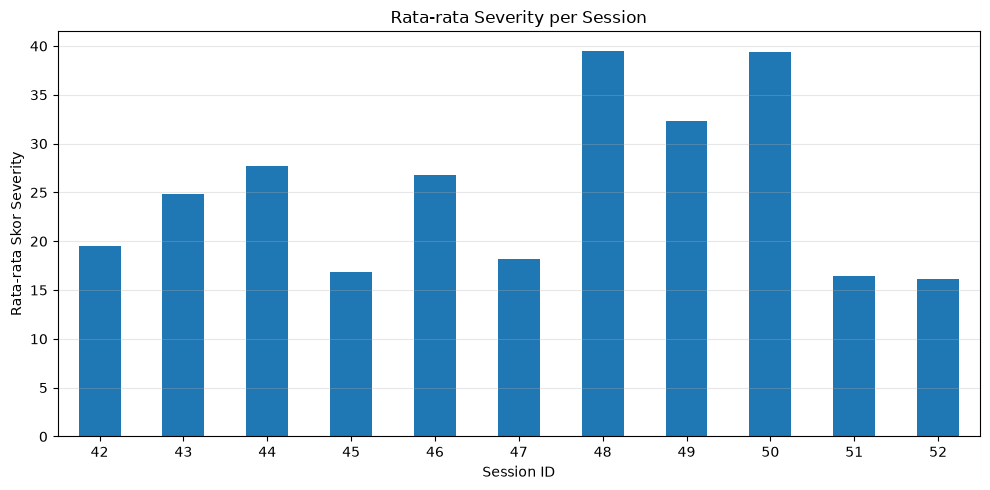

In [98]:
rata_severity = (
    df_severity.groupby("session_id")["skor_severity_tanpa_barometer"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(10, 5))
rata_severity.plot(kind="bar")

plt.title("Rata-rata Severity per Session")
plt.xlabel("Session ID")
plt.ylabel("Rata-rata Skor Severity")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [99]:
print("===== VALIDASI SEVERITY SCORING =====")

print("Jumlah data:", len(df_severity))

print("\nNilai kosong:")
print(df_severity[
    ["skor_severity_tanpa_barometer", "tingkat_severity_final"]
].isnull().sum())

print("\nRentang skor:")
print(df_severity["skor_severity_tanpa_barometer"].describe())

print("\nKategori Severity:")
print(df_severity["tingkat_severity_final"].value_counts())

===== VALIDASI SEVERITY SCORING =====
Jumlah data: 3403

Nilai kosong:
skor_severity_tanpa_barometer    0
tingkat_severity_final           0
dtype: int64

Rentang skor:
count    3403.000000
mean       34.873107
std        10.375949
min        13.879585
25%        36.500000
50%        36.500000
75%        42.558020
max        85.000000
Name: skor_severity_tanpa_barometer, dtype: float64

Kategori Severity:
tingkat_severity_final
Sedang    2660
Rendah     732
Tinggi      11
Name: count, dtype: int64


In [100]:
ringkasan_deteksi = pd.DataFrame({
    "Metode": [
        "Rule-Based",
        "Isolation Forest",
        "Hybrid AI"
    ],
    "Data Normal": [
        (~df_hybrid["rule_based_anomaly"]).sum(),
        (~df_hybrid["ai_anomaly"]).sum(),
        (~df_hybrid["hybrid_anomaly"]).sum()
    ],
    "Data Anomali": [
        df_hybrid["rule_based_anomaly"].sum(),
        df_hybrid["ai_anomaly"].sum(),
        df_hybrid["hybrid_anomaly"].sum()
    ]
})

ringkasan_deteksi["Total Data"] = (
    ringkasan_deteksi["Data Normal"] +
    ringkasan_deteksi["Data Anomali"]
)

print("===== PERBANDINGAN HASIL DETEKSI =====")
display(ringkasan_deteksi)

===== PERBANDINGAN HASIL DETEKSI =====


,Metode,Data Normal,Data Anomali,Total Data
0,Rule-Based,8804,2611,11415
1,Isolation Forest,9883,1532,11415
2,Hybrid AI,8012,3403,11415


In [101]:
print("===== RINGKASAN AKHIR HYBRID AI + SEVERITY =====")

print("Total Data Testing:", len(df_hybrid))
print("Total Kandidat Anomali:", len(df_severity))

print("\nDistribusi Severity:")
display(
    df_severity["tingkat_severity_final"]
    .value_counts()
    .reindex(["Rendah", "Sedang", "Tinggi"], fill_value=0)
    .rename_axis("Tingkat Severity")
    .to_frame("Jumlah Data")
)

print("\nRata-rata Skor Severity:",
      round(df_severity["skor_severity_tanpa_barometer"].mean(), 2))

print("Skor Severity Tertinggi:",
      round(df_severity["skor_severity_tanpa_barometer"].max(), 2))

===== RINGKASAN AKHIR HYBRID AI + SEVERITY =====
Total Data Testing: 11415
Total Kandidat Anomali: 3403

Distribusi Severity:


,Jumlah Data
Tingkat Severity,
Rendah,732
Sedang,2660
Tinggi,11



Rata-rata Skor Severity: 34.87
Skor Severity Tertinggi: 85.0


In [102]:
ringkasan_akhir = pd.DataFrame({
    "Informasi": [
        "Total Data Testing",
        "Rule-Based Anomali",
        "Isolation Forest Anomali",
        "Hybrid AI Anomali",
        "Severity Rendah",
        "Severity Sedang",
        "Severity Tinggi",
        "Rata-rata Skor Severity",
        "Skor Severity Tertinggi"
    ],
    "Nilai": [
        len(df_hybrid),
        int(df_hybrid["rule_based_anomaly"].sum()),
        int(df_hybrid["ai_anomaly"].sum()),
        int(df_hybrid["hybrid_anomaly"].sum()),
        int((df_severity["tingkat_severity_final"] == "Rendah").sum()),
        int((df_severity["tingkat_severity_final"] == "Sedang").sum()),
        int((df_severity["tingkat_severity_final"] == "Tinggi").sum()),
        round(df_severity["skor_severity_tanpa_barometer"].mean(), 2),
        round(df_severity["skor_severity_tanpa_barometer"].max(), 2)
    ]
})

ringkasan_akhir.to_csv(
    "outputs/ringkasan_akhir_project.csv",
    index=False
)

print("Ringkasan akhir berhasil disimpan!")
display(ringkasan_akhir)

Ringkasan akhir berhasil disimpan!


,Informasi,Nilai
0,Total Data Testing,11415.00
1,Rule-Based Anomali,2611.00
2,Isolation Forest Anomali,1532.00
3,Hybrid AI Anomali,3403.00
4,Severity Rendah,732.00
5,Severity Sedang,2660.00
6,Severity Tinggi,11.00
7,Rata-rata Skor Severity,34.87
8,Skor Severity Tertinggi,85.00



# 10. Kesimpulan Evaluasi Model

Berdasarkan hasil evaluasi pada 11.415 data testing, diperoleh hasil:

1. Rule-Based mendeteksi 6.265 kandidat anomali (54,88%).
2. Isolation Forest mendeteksi 1.243 kandidat anomali (10,89%).
3. Hybrid AI mendeteksi 6.547 kandidat anomali (57,35%).

Hasil perbandingan Rule-Based dan Isolation Forest menunjukkan:
- 961 data terdeteksi anomali oleh kedua metode.
- 5.304 data hanya terdeteksi Rule-Based.
- 282 data hanya terdeteksi Isolation Forest.
- 4.868 data dinyatakan normal oleh kedua metode.

Tingkat kesesuaian kedua metode sebesar 51,06%.

Pemeriksaan khusus pada session 48 dan 50 menunjukkan adanya pergeseran distribusi barometer dan TVOC. Rule-Based menandai seluruh data pada kedua sesi sebagai kandidat anomali, sedangkan Isolation Forest memberikan deteksi yang lebih selektif.

## 11. Keterbatasan Evaluasi

1. Dataset belum memiliki label ground truth sehingga akurasi, precision, recall, dan F1-score belum dapat dihitung secara valid.
2. Hasil deteksi merupakan kandidat anomali yang masih membutuhkan pemeriksaan lebih lanjut.
3. Threshold Rule-Based masih menggunakan batas yang ditentukan berdasarkan karakteristik dataset.
4. Isolation Forest belum dapat memastikan apakah suatu kondisi merupakan kerusakan sensor atau perubahan lingkungan yang sebenarnya.

## 12. Kesimpulan Akhir

Metode Hybrid AI menggabungkan hasil deteksi Rule-Based dan Isolation Forest untuk memperoleh kandidat anomali dari berbagai karakteristik data sensor.

Hasil pengembangan ini menjadi dasar untuk membangun pipeline deteksi anomali dan mengintegrasikannya dengan Telegram Bot agar hasil deteksi dapat dilaporkan secara otomatis.
